# Стадия 1. Анализ данных о пациентах с циррозом печени

**Источник данных:** синтетический набор на основе клинического исследования цирроза печени
(публикация Kaggle, идентификатор набора `playground-series-s3e26`); первоисточник -
*Cirrhosis Patient Survival Prediction* (UCI Machine Learning Repository).

**О чём данные.** 7 905 пациентов с первичным билиарным циррозом — хроническим заболеванием печени. По каждому пациенту записаны возраст, пол, принимаемый препарат, результаты анализов крови, признаки болезни (асцит, увеличение печени, сосудистые «паучки», отёки), стадия поражения печени и **итог наблюдения**: пациент жив, жив благодаря пересадке печени или умер.

**Конечная цель работы** — научиться по результатам обследования предсказывать, сохранится ли у пациента своя печень: 0 — пациент жив без трансплантации, 1 — трансплантация или смерть. Эта стадия готовит к тому фундамент.

---

## Задачи этой стадии

1. **Проверить, что данным можно доверять.** Нет ли пропусков, противоречий, физически невозможных значений (например, отрицательного числа тромбоцитов).

2. **Понять, как устроены данные.** Как распределены показатели, какие из них связаны с исходом, как связаны между собой.

3. **Привести данные в порядок.** Удалить записи, противоречащие протоколу исследования, и сделать показатели удобными для сравнения.

4. **Отобрать признаки для модели.** Это главная практическая задача стадии. Из 35 столбцов очищенного датасета нужно оставить такой набор, в котором:
   - нет столбцов, повторяющих друг друга (иначе одна и та же информация будет учтена дважды);
   - нет столбцов, не связанных с исходом;
   - нет столбцов, которые «подглядывают» в ответ — содержат информацию, известную только после наступления исхода.

5. **Разобраться с периодом наблюдения** — сколько дней пациент состоял под наблюдением. Этот столбец выглядит очень полезным, но его природа требует отдельного решения (блок 3.8).

## Что получается на выходе

| Файл | Содержимое | Для чего |
|---|---|---|
| `data/processed/train_clean.parquet` | все 35 столбцов после очистки (включая исходный `Status` и бинарную цель `Event`) | графики и проверки этой стадии |
| `data/processed/train_model.parquet` | 15 отобранных признаков и бинарная цель `Event` | вход моделей стадий 2, 3 и 4 |

Дальше идут три стадии: **стадия 2** проверяет, применим ли к задаче самый простой линейный метод (оценка по числу), **стадия 3** строит корректную модель предсказания исхода и **стадия 4** проверяет, можно ли повысить качество модели за счёт полиномиальных признаков и регуляризации.

# **Часть 1. Загрузка данных**

## **1.1 Импорты и настройки**

In [1]:
# Стандартная библиотека Python
from math import pi
import os

# Сторонние библиотеки для анализа данных и визуализации
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Единое зерно случайности для всего ноутбука: выборки, разбиения, кросс-валидация.
# Значение не меняется между прогонами и стадиями, поэтому результаты сравнимы.
RANDOM_STATE = 42


## **1.2 Скачивание датасета из Kaggle**

In [2]:
# 1. Авторизация в Kaggle
kagglehub.login()

# 2. Корень проекта: папка с data/, найденная вверх по дереву от текущей директории.
#    Ноутбук лежит в project_notebooks/, данные — в data/ на уровень выше,
#    поэтому os.getcwd() напрямую использовать нельзя.
def find_project_root(start=None):
    d = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isdir(os.path.join(d, 'data')):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            raise FileNotFoundError('Папка data/ не найдена вверх по дереву от ' + d)
        d = parent

PROJECT_ROOT = find_project_root()
local_dir = os.path.join(PROJECT_ROOT, 'data')
print('Корень проекта:', PROJECT_ROOT)

# 3. Скачивание файлов (раскомментировать для первичной загрузки)
# path = kagglehub.competition_download(
#     "playground-series-s3e26",
#     output_dir=local_dir,
#     force_download=True
# )
# print("Файлы успешно скачаны в:", path)
# print("Список файлов:", os.listdir(path))

Корень проекта: /media/gregory/Custom disk/repository/project1/ml-project-practice-1


In [3]:
# Загрузка обучающей выборки
df = pd.read_csv(f"{local_dir}/train.csv", index_col=0)


## **1.3 Описание данных**

Датасет: **Multi-Class Prediction of Cirrhosis Outcomes** (публикация Kaggle, идентификатор набора `playground-series-s3e26`).
Исходная целевая переменная: `Status` (три класса).
Цель моделирования: бинарная переменная `Event` — 0, если пациент жив со своей печенью (`C`), 1, если перенёс трансплантацию или умер (`CL` или `D`). Обоснование перехода — блок 3.9.

**Фактические параметры выборки `train.csv`:** 7 905 строк × 19 столбцов (+ `id` как индекс), пропусков нет; типы при загрузке: int64(2) — `N_Days`, `Age`, float64(10) — лабораторные показатели, `Platelets`, `Stage`, object(7) — категориальные и целевая.

| Столбец | Тип | Описание |
|---------|-----|----------|
| `id` | int | Уникальный идентификатор записи (пациента). Не является признаком. |
| `N_Days` | int | Количество дней наблюдения за пациентом с момента регистрации до последнего визита или события (смерти/трансплантации). |
| `Drug` | categorical | Принимаемый препарат: `D-penicillamine` (D-пеницилламин) или `Placebo` (плацебо). |
| `Age` | int | Возраст пациента в **днях** (не в годах!). Для перевода в годы: `Age / 365.25`. |
| `Sex` | categorical | Пол пациента: `M` (мужской) или `F` (женский). |
| `Ascites` | categorical | Наличие асцита (скопления жидкости в брюшной полости): `Y` / `N`. |
| `Hepatomegaly` | categorical | Наличие гепатомегалии (увеличения печени): `Y` / `N`. |
| `Spiders` | categorical | Наличие сосудистых «паучков» (spider angiomata) на коже: `Y` / `N`. |
| `Edema` | categorical | Наличие отёков: `N` (нет), `S` (есть, но купируется диуретиками), `Y` (есть, несмотря на диуретики). |
| `Bilirubin` | float | Уровень билирубина в сыворотке крови, мг/дл. |
| `Cholesterol` | float | Уровень холестерина в сыворотке, мг/дл. |
| `Albumin` | float | Уровень альбумина в сыворотке, г/дл. |
| `Copper` | float | Уровень меди в моче, мкг/дл. |
| `Alk_Phos` | float | Щелочная фосфатаза (alkaline phosphatase), Ед/л. |
| `SGOT` | float | Аспартатаминотрансфераза (AST/SGOT), Ед/мл. |
| `Tryglicerides` | float | Уровень триглицеридов в сыворотке, мг/дл. |
| `Platelets` | float | Количество тромбоцитов (×1000/мкл). В CSV значения целые (62–598), но тип float64. |
| `Prothrombin` | float | Протромбиновое время, секунды (стандартизированное). |
| `Stage` | float | Стадия фиброза/цирроза по гистологии: 1.0, 2.0, 3.0 или 4.0 (чем выше — тем тяжелее). Хранится как float64, целочисленных значений в CSV нет. |
| `Status` | categorical | **Целевая переменная**: `C` — пациент жив на момент `N_Days` (цензурирован); `CL` — жив благодаря трансплантации печени; `D` — умер. |

### Примечания по предобработке

- **Целевая переменная** `Status` имеет три класса: `C`, `CL`, `D`. Для моделирования они объединяются в бинарную цель `Event`: 0 — `C`, 1 — `CL` или `D` (выживание со своей печенью против трансплантации или смерти).
- **Категориальные признаки** (`Drug`, `Sex`, `Ascites`, `Hepatomegaly`, `Spiders`, `Edema`) представлены строками — их необходимо закодировать (One-Hot / Label Encoding) перед подачей в модель.
- **`Edema`** имеет три уровня (`N`, `S`, `Y`), а не два — это стоит учитывать при кодировании (порядковая шкала `0 / 0.5 / 1`).
- **`Age`** задан в днях; для интерпретации и инженерии признаков удобно перевести в годы.
- **`id`** — технический столбец, его следует исключить из признаков.
- Исходный датасет — *Cirrhosis Patient Survival Prediction* (UCI); рабочие данные сгенерированы глубокой моделью на его основе и имеют близкие, но не идентичные распределения.

Датасет содержит 7 905 записей о пациентах с циррозом печени. Целевая переменная `Status` имеет три класса: `C` — 4 965 (62.8 %), `D` — 2 665 (33.7 %), `CL` — 275 (3.5 %). Ключевые предикторы: стадия фиброза, лабораторные показатели и клинические признаки. Данные синтетические, сгенерированы на основе UCI Cirrhosis.

# **Часть 2. Первичный осмотр данных**

## **2.1 Первый взгляд на данные**

In [4]:
df.head()

,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status
id,,,,,,,,,,,,,,,,,,,
0,999,D-penicillamine,21532,M,N,N,N,N,2.3,316.0,3.35,172.0,1601.0,179.80,63.0,394.0,9.7,3.0,D
1,2574,Placebo,19237,F,N,N,N,N,0.9,364.0,3.54,63.0,1440.0,134.85,88.0,361.0,11.0,3.0,C
2,3428,Placebo,13727,F,N,Y,Y,Y,3.3,299.0,3.55,131.0,1029.0,119.35,50.0,199.0,11.7,4.0,D
3,2576,Placebo,18460,F,N,N,N,N,0.6,256.0,3.50,58.0,1653.0,71.30,96.0,269.0,10.7,3.0,C
4,788,Placebo,16658,F,N,Y,N,N,1.1,346.0,3.65,63.0,1181.0,125.55,96.0,298.0,10.6,4.0,C


In [5]:
# Случайная выборка — всегда смотрим разные срезы
df.sample(5, random_state=RANDOM_STATE)


,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status
id,,,,,,,,,,,,,,,,,,,
3467,971,D-penicillamine,20555,F,N,N,N,N,0.8,328.0,3.50,65.0,688.0,60.45,213.0,265.0,9.8,3.0,C
465,1810,D-penicillamine,20555,F,N,Y,Y,N,3.3,361.0,3.57,34.0,12258.8,72.85,104.0,341.0,10.6,4.0,C
453,2176,Placebo,17263,M,N,N,N,N,1.2,232.0,3.98,11.0,1074.0,100.75,99.0,223.0,9.9,3.0,C
4913,1462,Placebo,23331,F,N,N,N,N,0.4,258.0,3.74,49.0,559.0,43.40,177.0,284.0,10.5,3.0,D
5907,1216,Placebo,19994,F,N,Y,N,N,0.7,336.0,3.36,44.0,1826.0,97.65,110.0,256.0,9.5,1.0,C


## **2.2 Технический паспорт данных**

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7905 entries, 0 to 7904
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   N_Days         7905 non-null   int64  
 1   Drug           7905 non-null   object 
 2   Age            7905 non-null   int64  
 3   Sex            7905 non-null   object 
 4   Ascites        7905 non-null   object 
 5   Hepatomegaly   7905 non-null   object 
 6   Spiders        7905 non-null   object 
 7   Edema          7905 non-null   object 
 8   Bilirubin      7905 non-null   float64
 9   Cholesterol    7905 non-null   float64
 10  Albumin        7905 non-null   float64
 11  Copper         7905 non-null   float64
 12  Alk_Phos       7905 non-null   float64
 13  SGOT           7905 non-null   float64
 14  Tryglicerides  7905 non-null   float64
 15  Platelets      7905 non-null   float64
 16  Prothrombin    7905 non-null   float64
 17  Stage          7905 non-null   float64
 18  Status       

### Анализ `.info()`:

| Метрика | Значение | Вывод |
|---------|----------|-------|
| **Типы данных** | float64(10), int64(2), object(7) | OK, но можно оптимизировать |
| **Пропуски** | отсутствуют в train.csv | Проверим в блоке 3.1 |
| **Размер** | 7 905 строк × 19 признаков | Достаточно для всех методов EDA |
| **Index** | `id` (int) | Технический столбец, исключается из признаков |

## **2.3 Статистическая сводка**

In [7]:
# Числовые переменные
df.describe().T


,count,mean,std,min,25%,50%,75%,max
N_Days,7905.0,2030.173308,1094.233744,41.00,1230.00,1831.00,2689.00,4795.00
Age,7905.0,18373.146490,3679.958739,9598.00,15574.00,18713.00,20684.00,28650.00
Bilirubin,7905.0,2.594485,3.812960,0.30,0.70,1.10,3.00,28.00
Cholesterol,7905.0,350.561923,195.379344,120.00,248.00,298.00,390.00,1775.00
Albumin,7905.0,3.548323,0.346171,1.96,3.35,3.58,3.77,4.64
Copper,7905.0,83.902846,75.899266,4.00,39.00,63.00,102.00,588.00
Alk_Phos,7905.0,1816.745250,1903.750657,289.00,834.00,1181.00,1857.00,13862.40
SGOT,7905.0,114.604602,48.790945,26.35,75.95,108.50,137.95,457.25
Tryglicerides,7905.0,115.340164,52.530402,33.00,84.00,104.00,139.00,598.00
Platelets,7905.0,265.228969,87.465579,62.00,211.00,265.00,316.00,563.00


In [8]:
# Категориальные переменные
df.describe(include=['object', 'category']).T


,count,unique,top,freq
Drug,7905,2,Placebo,4010
Sex,7905,2,F,7336
Ascites,7905,2,N,7525
Hepatomegaly,7905,2,Y,4042
Spiders,7905,2,N,5966
Edema,7905,3,N,7161
Status,7905,3,C,4965


## **2.5 Инженерия признаков (базовая)**

Перед полноценным анализом добавим несколько признаков, которые упрощают интерпретацию и последующее моделирование:

- `Age_years` — возраст в годах (исходный `Age` задан в днях). **Зачем:** человеческий масштаб для графиков и выводов; подписи осей в днях нечитаемы.
- `Edema_num` — порядковый код отёка (`N=0`, `S=0.5`, `Y=1`). **Зачем:** перевод порядковой категориальной шкалы в числовую, чтобы признак участвовал в корреляциях и линейных моделях без разбиения на несколько столбцов.
- `is_severe` — бинарный флаг тяжёлой стадии (`Stage >= 3`). **Зачем:** компактная группа для сегментного анализа (radar-сравнения в блоке 6.3).
- `is_dead` — бинарный флаг летального исхода (`Status == 'D'`). **Зачем:** событийный индикатор для Kaplan-Meier и сравнения профилей «умершие vs выжившие».
- `log_*` — логарифмические варианты правосторонне скошенных лабораторных признаков. **Зачем:** уменьшают скошенность и стабилизируют дисперсию — это улучшает применимость корреляции Пирсона и линейных моделей.

> **Предупреждение.** Каждый из этих признаков пересказывает уже имеющиеся данные, а не добавляет новые. Если положить в модель и исходный показатель, и его копию, одна и та же информация будет учтена дважды: модель начнёт считать её вдвое более важной, а веса при признаках станут нестабильными. Поэтому ниже каждый признак проверяется на дублирование, а в блок 2.5 добавлено правило отбора — см. таблицу после проверки.

In [9]:
# 1. Возраст в годах
df['Age_years'] = (df['Age'] / 365.25).round(1)

# 2. Порядковый код Edema: N=0, S=0.5, Y=1
df['Edema_num'] = df['Edema'].map({'N': 0.0, 'S': 0.5, 'Y': 1.0}).astype('float32')

# 3. Бинарные флаги для сегментированного анализа
df['is_severe'] = (df['Stage'] >= 3).astype('int8')
df['is_dead'] = (df['Status'] == 'D').astype('int8')

# 4. Лог-преобразования для правосторонне скошенных признаков
log_cols = ['Bilirubin', 'Copper', 'Alk_Phos', 'SGOT', 'Cholesterol', 'Tryglicerides']
for c in log_cols:
    df[f'log_{c}'] = np.log1p(df[c])

# 5. Бинарный код пола: M=1, F=0
df['Sex_M'] = (df['Sex'] == 'M').astype('int8')

# 6. Бинарный код признаков «да/нет» (1 = признак есть)
for col in ['Ascites', 'Hepatomegaly', 'Spiders']:
    df[f'{col}_Y'] = (df[col] == 'Y').astype('int8')

# 7. Кандидаты в матрицу модели: по одному представителю каждой пары
#    (обоснование — таблица ниже). Ascites_Y пока входит: решение по паре
#    «асцит — отёки» принимается в блоке 3.11.
MODEL_NUM = ['log_Bilirubin', 'log_Copper', 'log_Alk_Phos', 'log_SGOT',
             'log_Cholesterol', 'log_Tryglicerides',
             'Albumin', 'Platelets', 'Prothrombin',
             'Age_years', 'Stage', 'Edema_num',
             'Sex_M', 'Ascites_Y', 'Hepatomegaly_Y', 'Spiders_Y']

df[list(df.columns)[-13:]].head()

,Edema_num,is_severe,is_dead,log_Bilirubin,log_Copper,log_Alk_Phos,log_SGOT,log_Cholesterol,log_Tryglicerides,Sex_M,Ascites_Y,Hepatomegaly_Y,Spiders_Y
id,,,,,,,,,,,,,
0,0.0,1,1,1.193922,5.153292,7.379008,5.197391,5.758902,4.158883,1,0,0,0
1,0.0,1,0,0.641854,4.158883,7.273093,4.911551,5.899897,4.488636,0,0,0,0
2,1.0,1,1,1.458615,4.882802,6.937314,4.790404,5.703782,3.931826,0,0,1,1
3,0.0,1,0,0.470004,4.077537,7.410952,4.280824,5.549076,4.574711,0,0,0,0
4,0.0,1,0,0.741937,4.158883,7.074963,4.840637,5.849325,4.574711,0,0,1,0


### Проверка необходимости инженерных признаков

Инженерный признак полезен в двух ролях: (а) делает данные удобнее для человека и моделей, (б) добавляет новую информацию о связях. Проверим вторую роль: сравним каждый производный признак с исходным. Если связь детерминированная или монотонная — новой информации нет, и в матрице φk (блок 5.1) такой признак только дублирует исходный.

In [10]:
# 1. Age_years vs Age: линейное перемасштабирование (дни -> годы)
print('Age_years vs Age:')
print(f"  Pearson r    = {df['Age_years'].corr(df['Age']):.4f}")
print(f"  Spearman rho = {df['Age_years'].corr(df['Age'], method='spearman'):.4f}")
print('  Вывод: новой информации нет (отличие от 1.0 — только округление до 0.1 года),\n'
        '  но возраст в годах читаем на графиках и порогах.')

# 2. Edema_num vs Edema: взаимно однозначное отображение
print('\nEdema_num vs Edema:')
display(pd.crosstab(df['Edema'], df['Edema_num']))
print('  Вывод: кодирование порядковой шкалы — новой информации нет,\n'
        '  но числовой вид позволяет признаку входить в корреляции и модели.')

# 3. is_severe vs Stage: детерминированная функция
print('\nis_severe vs Stage:')
display(pd.crosstab(df['Stage'], df['is_severe']))
print('  Вывод: is_severe полностью определяется Stage — дубль для φk-матрицы,\n'
        '  нужен только как удобный срез для сегментного анализа (блок 6.3).')

# 4. is_dead vs Status: детерминированная функция
print('\nis_dead vs Status:')
display(pd.crosstab(df['Status'], df['is_dead']))
print('  Вывод: is_dead полностью определяется Status — дубль для φk-матрицы,\n'
        '  нужен как событийный индикатор (Kaplan-Meier, радар-профили).')

# 5. log_* vs оригиналы: монотонное преобразование
comparison = pd.DataFrame({
    'spearman(log_c, c)': [df[c].corr(df[f'log_{c}'], method='spearman') for c in log_cols],
    'skew оригинал': [df[c].skew() for c in log_cols],
    'skew log1p': [df[f'log_{c}'].skew() for c in log_cols],
}, index=log_cols)
print('\nlog_* vs оригиналы:')
display(comparison.round(3))
print('  Вывод: Spearman = 1 — ранговый порядок не меняется, новых связей нет;\n'
        '  зато скошенность резко снижается, и признаки становятся пригодны для\n'
        '  корреляции Пирсона и линейных моделей.')

# 6. Какой вариант лог-пары лучше описывает связь с целью
# Цель временно кодируем числами только для расчёта корреляции (модели здесь нет)
y_num = df['Status'].astype(str).map({'C': 0, 'CL': 1, 'D': 2})
lin = pd.DataFrame({
    'связь исходного': [y_num.corr(df[c]) for c in log_cols],
    'связь log-варианта': [y_num.corr(df[f'log_{c}']) for c in log_cols],
}, index=log_cols)
lin['выигрыш log'] = lin['связь log-варианта'].abs() - lin['связь исходного'].abs()
print('\nЛинейность связи с целью (Пирсон, по модулю):')
display(lin.round(3))
print('  Вывод: лог-вариант описывает связь с целью не хуже, а для билирубина —')
print('  заметно лучше (0.53 против 0.43). Значит, в модель берём log-вариант.')

print('\n' + '=' * 60)
print('ИТОГ: ни один инженерный признак не добавляет новых связей — это пересказ')
print('уже имеющихся данных. Роль признаков — удобство интерпретации, сегментации')
print('и применимость линейных методов.')
print('Значит, в модель берём ОДИН вариант из каждой пары (см. таблицу ниже).')

Age_years vs Age:
  Pearson r    = 1.0000
  Spearman rho = 1.0000
  Вывод: новой информации нет (отличие от 1.0 — только округление до 0.1 года),
  но возраст в годах читаем на графиках и порогах.

Edema_num vs Edema:


Edema_num,0.0,0.5,1.0
Edema,,,
N,7161,0,0
S,0,399,0
Y,0,0,345


  Вывод: кодирование порядковой шкалы — новой информации нет,
  но числовой вид позволяет признаку входить в корреляции и модели.

is_severe vs Stage:


is_severe,0,1
Stage,,
1.0,397,0
2.0,1652,0
3.0,0,3153
4.0,0,2703


  Вывод: is_severe полностью определяется Stage — дубль для φk-матрицы,
  нужен только как удобный срез для сегментного анализа (блок 6.3).

is_dead vs Status:


is_dead,0,1
Status,,
C,4965,0
CL,275,0
D,0,2665


  Вывод: is_dead полностью определяется Status — дубль для φk-матрицы,
  нужен как событийный индикатор (Kaplan-Meier, радар-профили).

log_* vs оригиналы:


,"spearman(log_c, c)",skew оригинал,skew log1p
Bilirubin,1.0,3.340,1.422
Copper,1.0,2.702,0.041
Alk_Phos,1.0,3.196,1.001
SGOT,1.0,1.535,0.018
Cholesterol,1.0,3.680,1.277
Tryglicerides,1.0,2.634,0.373


  Вывод: Spearman = 1 — ранговый порядок не меняется, новых связей нет;
  зато скошенность резко снижается, и признаки становятся пригодны для
  корреляции Пирсона и линейных моделей.

Линейность связи с целью (Пирсон, по модулю):


,связь исходного,связь log-варианта,выигрыш log
Bilirubin,0.429,0.534,0.104
Copper,0.386,0.414,0.028
Alk_Phos,0.155,0.224,0.070
SGOT,0.313,0.328,0.015
Cholesterol,0.185,0.178,-0.006
Tryglicerides,0.197,0.200,0.003


  Вывод: лог-вариант описывает связь с целью не хуже, а для билирубина —
  заметно лучше (0.53 против 0.43). Значит, в модель берём log-вариант.

ИТОГ: ни один инженерный признак не добавляет новых связей — это пересказ
уже имеющихся данных. Роль признаков — удобство интерпретации, сегментации
и применимость линейных методов.
Значит, в модель берём ОДИН вариант из каждой пары (см. таблицу ниже).


Первичный осмотр показал, что датасет содержит 19 исходных столбцов (10 числовых, 7 категориальных, 1 порядковый `Stage`, 1 целевой `Status`), пропусков нет. Оптимизация памяти через приведение типов снижает потребление памяти почти втрое.

**Проверка подтвердила:** ни один из девяти добавленных признаков не содержит новой информации — все они получаются из уже имеющихся столбцов без потерь и без остатка. Это не ошибка, а ожидаемое свойство таких преобразований: логарифм, перевод дней в годы или код «тяжёлая стадия» ничего нового про пациента не рассказывают.

**Отсюда практическое следствие.** Раз признаки дублируют друг друга, в модель их надо класть по одному из пары — иначе одна и та же информация будет посчитана дважды. Таблица ниже фиксирует, какой именно вариант выбран по каждой паре и почему. Это решение действует во всех трёх стадиях работы.

### Какое представление каждого признака пойдёт в модель

Проверка выше показала, что **ни один** инженерный признак не добавляет новой информации о связях — все они пересказ уже имеющихся данных. Значит, в модель можно взять только один вариант из каждой пары. Иначе одна и та же информация учитывается дважды.

**Почему дублирование вредит модели.** Линейная модель складывает признаки с весами. Если в матрице лежат `Bilirubin` и `log_Bilirubin` (их ранговая связь равна 1), модель не может понять, какой из них «настоящий», и распределяет один и тот же эффект между двумя столбцами с противоположными знаками. Вес перестаёт отвечать на вопрос «как этот показатель влияет на исход», а небольшое изменение данных перекашивает оба веса. Это же делает бесполезной и интерпретацию, и сравнение моделей.

**Правило отбора: одна информация — один столбец.**

| Информация | Варианты в датасете | Берём в модель | Почему именно этот |
|---|---|---|---|
| Билирубин, медь, щелочная фосфатаза, AST, холестерин, триглицериды (6 показателей) | исходный и `log_` (6 пар) | **`log_`-вариант** | связь с целью описывается линейной моделью не хуже исходной (для билирубина: 0.53 против 0.43), при этом сильные отклонения отдельных пациентов не искажают расчёт |
| Возраст | `Age` (дни), `Age_years` (годы) | **`Age_years`** | одинаковая информация, но читаемый масштаб |
| Стадия фиброза | `Stage` (1-4), `is_severe` (0/1) | **`Stage`** | `is_severe` выбрасывает различие между стадиями 1 и 2, 3 и 4 — потеря информации |
| Отёки | `Edema` (три категории), `Edema_num` (0 / 0.5 / 1) | **`Edema_num`** | категории упорядочены по тяжести, один столбец вместо двух; по качеству модели варианты равны (проверка в блоке 3.11) |
| Исход наблюдения | `Status` (цель), `is_dead` (0/1) | **только `Status`** | `is_dead` — это половина ответа на вопрос задачи, его использование в модели даёт заведомо ложный результат |

Признаки без копий (`Albumin`, `Platelets`, `Prothrombin`) берутся как есть: логарифм к ним не применялся, потому что их распределения близки к симметричным.

**Что делаем с остальными столбцами.** Исходные `Bilirubin`, `Copper`, `Alk_Phos`, `SGOT`, `Cholesterol`, `Tryglicerides`, `Age`, `Edema`, `is_severe` и `is_dead` остаются в файле `train_clean.parquet`: они нужны для графиков, таблиц и сегментного анализа этой стадии. Но в матрицу признаков моделей (стадии 2–8) они не попадают — там задаётся явный список из 15 признаков, и просочиться в модель дубликат не может.

# **Часть 3. Качество данных**

## **3.1 Анализ пропусков**

In [11]:
# Количество и доля пропусков по каждому столбцу
missing_count = df.isna().sum()
missing_pct = (df.isna().mean() * 100).round(2)

missing_df = pd.DataFrame({
    'Пропуски': missing_count,
    '%': missing_pct
}).query('Пропуски > 0').sort_values('Пропуски', ascending=False)

print('Пропуски в данных:')
missing_df


Пропуски в данных:


,Пропуски,%


### Вывод по пропускам

В `train.csv` пропусков нет — данные переданы уже заполненными (генеративная модель источника восстановила отсутствовавшие значения). Проверка на нулевые и отрицательные показатели выполнена в блоках 3.2 и 3.4.

## **3.2 Проверка аномальных значений**

In [12]:
# Гарантируем, что id — обычная колонка
if 'id' not in df.columns:
    df = df.reset_index()

# Колонки, реально присутствующие в датафрейме (защита от опечаток)
available_cols = set(df.columns)

def cols_present(cols):
    return [c for c in cols if c in available_cols]

def check_anomaly(mask, title, cols=None):
    subset = df[mask]
    print(f"{title}: {len(subset)}")
    if len(subset) > 0:
        cols_use = cols_present(cols) if cols else None
        display(subset if cols_use is None else subset[cols_use])
    print('-' * 60)

# 1. Нулевые и отрицательные значения лабораторных показателей
check_anomaly(df['Bilirubin'] == 0, "Пациенты с Bilirubin = 0")
check_anomaly(df['Albumin'] == 0, "Пациенты с Albumin = 0")
check_anomaly(df['Platelets'] == 0, "Пациенты с Platelets = 0")
check_anomaly(df['Prothrombin'] == 0, "Пациенты с Prothrombin = 0")
check_anomaly(df['Cholesterol'] == 0, "Пациенты с Cholesterol = 0")
check_anomaly(df['Tryglicerides'] <= 0, "Пациенты с Tryglicerides <= 0")

# 2. Несоответствие возрастного диапазона исследования
check_anomaly(df['Age'] < 6570, "Пациенты младше 18 лет (Age < 6570 дней)")

# 3. Аномальные значения времени наблюдения
check_anomaly(df['N_Days'] == 0, "Пациенты с N_Days = 0")

# 4. Некорректные значения Stage
check_anomaly(~df['Stage'].isin([1, 2, 3, 4]), "Пациенты со Stage вне {1, 2, 3, 4}")

# 5. Клинически экстремальные значения
check_anomaly(df['Bilirubin'] > 20,
              "Пациенты с Bilirubin > 20 (тяжёлая желтуха)",
              cols=['id', 'Bilirubin', 'Albumin', 'Stage', 'Status'])
check_anomaly(df['Alk_Phos'] > 10000,
              "Пациенты с Alk_Phos > 10000",
              cols=['id', 'Alk_Phos', 'Bilirubin', 'Stage', 'Status'])
check_anomaly(df['SGOT'] > 1000,
              "Пациенты с SGOT > 1000",
              cols=['id', 'SGOT', 'Bilirubin', 'Stage', 'Status'])
check_anomaly(df['Copper'] > 500,
              "Пациенты с Copper > 500",
              cols=['id', 'Copper', 'Bilirubin', 'Stage', 'Status'])

# 6. Пропуски
print("Пропуски в данных:", df.isna().sum().sum(), "значений")


Пациенты с Bilirubin = 0: 0
------------------------------------------------------------
Пациенты с Albumin = 0: 0
------------------------------------------------------------
Пациенты с Platelets = 0: 0
------------------------------------------------------------
Пациенты с Prothrombin = 0: 0
------------------------------------------------------------
Пациенты с Cholesterol = 0: 0
------------------------------------------------------------
Пациенты с Tryglicerides <= 0: 0
------------------------------------------------------------
Пациенты младше 18 лет (Age < 6570 дней): 0
------------------------------------------------------------
Пациенты с N_Days = 0: 0
------------------------------------------------------------
Пациенты со Stage вне {1, 2, 3, 4}: 0
------------------------------------------------------------
Пациенты с Bilirubin > 20 (тяжёлая желтуха): 79


,id,Bilirubin,Albumin,Stage,Status
29,29,28.0,3.26,3.0,D
213,213,22.5,3.31,2.0,D
284,284,22.5,3.20,4.0,D
288,288,21.6,3.31,3.0,D
308,308,21.6,3.93,4.0,D
...,...,...,...,...,...
7287,7287,21.9,3.51,4.0,D
7572,7572,24.5,3.18,2.0,D
7585,7585,25.5,3.52,4.0,D
7740,7740,22.5,3.34,4.0,D


------------------------------------------------------------
Пациенты с Alk_Phos > 10000: 114


,id,Alk_Phos,Bilirubin,Stage,Status
105,105,10396.8,5.5,2.0,C
420,420,10165.0,1.1,2.0,C
447,447,11046.6,1.1,3.0,C
465,465,12258.8,3.3,4.0,C
482,482,11552.0,3.2,3.0,CL
...,...,...,...,...,...
7407,7407,11046.6,5.1,4.0,D
7425,7425,13862.4,1.3,3.0,C
7540,7540,12258.8,1.8,3.0,D
7729,7729,12258.8,0.8,3.0,C


------------------------------------------------------------
Пациенты с SGOT > 1000: 0
------------------------------------------------------------
Пациенты с Copper > 500: 26


,id,Copper,Bilirubin,Stage,Status
750,750,588.0,6.6,4.0,D
961,961,588.0,11.4,4.0,D
1034,1034,588.0,0.8,3.0,C
1191,1191,558.0,3.5,4.0,D
1264,1264,558.0,17.4,2.0,D
1701,1701,588.0,21.6,4.0,D
1955,1955,558.0,17.1,4.0,D
2239,2239,588.0,11.4,4.0,D
2575,2575,588.0,17.2,4.0,D
3523,3523,588.0,17.4,4.0,D


------------------------------------------------------------
Пропуски в данных: 0 значений


## **3.3 Структурные проверки**

Что ловим: опечатки в категориях (`'M '` vs `'M'`), лишние пробелы, неожиданные значения, дубликаты пациентов.

In [13]:
# 1.1 Уникальность id
print("Дубликатов id:", df['id'].duplicated().sum())

# 1.2 Полные дубликаты строк
print("Полных дубликатов строк:", df.duplicated().sum())

# 1.3 Типы данных
print(df.dtypes)

# 1.4 Пропуски
print(df.isna().sum())

# 1.5 Уникальные значения категориальных признаков
for c in ['Drug', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Status']:
    print(f"{c}: {df[c].unique()}  (n={df[c].nunique()})")

# 1.6 Stage как порядковая
print("Stage:", sorted(df['Stage'].unique()))


Дубликатов id: 0
Полных дубликатов строк: 0
id                     int64
N_Days                 int64
Drug                  object
Age                    int64
Sex                   object
Ascites               object
Hepatomegaly          object
Spiders               object
Edema                 object
Bilirubin            float64
Cholesterol          float64
Albumin              float64
Copper               float64
Alk_Phos             float64
SGOT                 float64
Tryglicerides        float64
Platelets            float64
Prothrombin          float64
Stage                float64
Status                object
Age_years            float64
Edema_num            float32
is_severe               int8
is_dead                 int8
log_Bilirubin        float64
log_Copper           float64
log_Alk_Phos         float64
log_SGOT             float64
log_Cholesterol      float64
log_Tryglicerides    float64
Sex_M                   int8
Ascites_Y               int8
Hepatomegaly_Y          int8

## **3.4 Медицинские границы**

Что ловим: нулевые/отрицательные значения, опечатки на порядок (например, `Alk_Phos = 13862.4` при норме до ~120), пациентов вне возрастного диапазона исследования.

In [14]:
# 2.1 Биологически невозможные значения
checks = {
    'Bilirubin':       (df['Bilirubin'] <= 0).sum(),
    'Cholesterol':     (df['Cholesterol'] <= 0).sum(),
    'Albumin':         (df['Albumin'] <= 0).sum(),
    'Copper':          (df['Copper'] <= 0).sum(),
    'Alk_Phos':        (df['Alk_Phos'] <= 0).sum(),
    'SGOT':            (df['SGOT'] <= 0).sum(),
    'Tryglicerides':   (df['Tryglicerides'] <= 0).sum(),
    'Platelets':       (df['Platelets'] <= 0).sum(),
    'Prothrombin':     (df['Prothrombin'] <= 0).sum(),
    'Age':             (df['Age'] <= 0).sum(),
    'N_Days':          (df['N_Days'] < 0).sum(),
}
print(pd.Series(checks, name='кол-во аномалий'))

# 2.2 Клинически допустимые диапазоны
ranges = {
    'Bilirubin':    (0.1, 30),
    'Albumin':      (1.5, 6),
    'Prothrombin':  (8, 20),
    'Platelets':    (50, 600),
    'Age':          (18*365, 100*365),  # дни
}
for col, (lo, hi) in ranges.items():
    out = ((df[col] < lo) | (df[col] > hi)).sum()
    print(f"{col}: вне [{lo}, {hi}] -> {out}")


Bilirubin        0
Cholesterol      0
Albumin          0
Copper           0
Alk_Phos         0
SGOT             0
Tryglicerides    0
Platelets        0
Prothrombin      0
Age              0
N_Days           0
Name: кол-во аномалий, dtype: int64
Bilirubin: вне [0.1, 30] -> 0
Albumin: вне [1.5, 6] -> 0
Prothrombin: вне [8, 20] -> 0
Platelets: вне [50, 600] -> 0
Age: вне [6570, 36500] -> 0


## **3.5 Согласованность категориальных и клинических признаков**

Что ловим: опечатки в категориях (`'y'`, `'Yes'`), несовместимые сочетания (лёгкий Stage с признаками тяжёлой декомпенсации), которые могут быть ошибками ввода.

In [15]:
# 3.1 Ascites / Hepatomegaly / Spiders должны быть {N, Y}
for c in ['Ascites', 'Hepatomegaly', 'Spiders']:
    bad = (~df[c].isin(['N', 'Y'])).sum()
    print(f"{c}: некорректных значений = {bad}")

# Edema имеет три уровня: {N, S, Y}
print("Edema:", df['Edema'].value_counts().to_dict())

# 3.2 Status — только {C, D, CL}
print("Status:", df['Status'].value_counts().to_dict())

# 3.3 Stage — только {1, 2, 3, 4}
print("Stage:", df['Stage'].value_counts().sort_index().to_dict())

# 3.4 Клиническая согласованность: тяжёлый асцит (Edema='Y'/'S') при нормальном Albumin
print("Edema=Y/S с Albumin > 3.5:",
      ((df['Edema'].isin(['Y', 'S'])) & (df['Albumin'] > 3.5)).sum())

# 3.5 Stage 4 vs Bilirubin (в среднем должно быть выше на поздних стадиях)
print(df.groupby('Stage')['Bilirubin'].agg(['mean', 'median', 'count']))


Ascites: некорректных значений = 0
Hepatomegaly: некорректных значений = 0
Spiders: некорректных значений = 0
Edema: {'N': 7161, 'S': 399, 'Y': 345}
Status: {'C': 4965, 'D': 2665, 'CL': 275}
Stage: {1.0: 397, 2.0: 1652, 3.0: 3153, 4.0: 2703}
Edema=Y/S с Albumin > 3.5: 242


           mean  median  count
Stage                         
1.0    1.449874     0.8    397
2.0    1.827845     0.9   1652
3.0    2.172598     0.9   3153
4.0    3.723270     2.0   2703


## **3.6 Статистические выбросы (IQR / z-score / MAD)**

Что ловим: формальные выбросы. **Важно:** в этом датасете большинство «выбросов» — клинически реальные тяжёлые пациенты, а не ошибки ввода.

In [16]:
num_cols = ['N_Days', 'Age', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper',
            'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin']

# 4.1 IQR-выбросы
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()

print(df[num_cols].apply(iqr_outliers).sort_values(ascending=False))

# 4.2 z-score > 3
z = np.abs(stats.zscore(df[num_cols], nan_policy='omit'))
print((z > 3).sum(axis=0))

# 4.3 Модифицированный z-score (MAD) — устойчивее к выбросам
def mad_outliers(s):
    med = s.median()
    mad = (s - med).abs().median()
    if mad == 0:
        return 0
    return ((0.6745 * (s - med) / mad).abs() > 3.5).sum()

print(df[num_cols].apply(mad_outliers))


Alk_Phos         792
Bilirubin        789
Copper           655
Cholesterol      502
Tryglicerides    267
Albumin          178
Prothrombin      173
SGOT             146
Platelets        114
Age               36
N_Days             0
dtype: int64
[  0   0 281 216 106 151 189  80 113  41 113]
N_Days              0
Age                 0
Bilirubin        1312
Cholesterol       426
Albumin            86
Copper            655
Alk_Phos          744
SGOT               80
Tryglicerides     143
Platelets          36
Prothrombin        67
dtype: int64


## **3.7 Странные multivariate-комбинации**

Что ловим: подозрительные сочетания, которые могут быть ошибками ввода (например, перепутаны единицы измерения у конкретного пациента).

In [17]:
# 6.1 Очень высокий Alk_Phos + нормальный Bilirubin (необычно при циррозе)
mask = (df['Alk_Phos'] > 5000) & (df['Bilirubin'] < 1.5)
print("Alk_Phos > 5000 и Bilirubin < 1.5:", mask.sum())
display(df.loc[mask, ['id', 'Alk_Phos', 'Bilirubin', 'Stage', 'Status']])

# 6.2 Очень высокий SGOT при нормальном Bilirubin
mask = (df['SGOT'] > 200) & (df['Bilirubin'] < 1.0)
print("SGOT > 200 и Bilirubin < 1:", mask.sum())

# 6.3 Плохой Prothrombin при статусе C (цензурирован)
mask = (df['Prothrombin'] >= 14) & (df['Status'] == 'C')
print("Prothrombin >= 14 при Status=C:", mask.sum())


Alk_Phos > 5000 и Bilirubin < 1.5: 357


,id,Alk_Phos,Bilirubin,Stage,Status
5,5,6456.2,0.6,3.0,D
53,53,5430.2,1.1,3.0,C
120,120,7277.0,0.6,3.0,C
125,125,5833.0,0.8,3.0,D
137,137,9066.8,0.7,4.0,D
...,...,...,...,...,...
7784,7784,12258.8,1.3,1.0,C
7837,7837,6121.8,0.7,4.0,D
7841,7841,7277.0,0.7,4.0,C
7850,7850,5430.2,0.8,3.0,C


SGOT > 200 и Bilirubin < 1: 61
Prothrombin >= 14 при Status=C: 5


## **3.8 Целевая переменная и период наблюдения**

Здесь проверяем две вещи: равновелики ли классы цели (от этого зависит выбор метрик и способ разбиения данных) и что собой представляет столбец `N_Days` — период наблюдения.

Вопрос про период не формальный. В датасете он выглядит как обычный признак: заполнен у всех пациентов, сильно связан с целью. Но у него особая природа — он измеряет время **до** завершения наблюдения, то есть становится известен только тогда, когда исход уже наступил. Разберём это отдельно и решим, можно ли использовать период при предсказании статуса.

In [18]:
# 1. Баланс классов целевой переменной
balance = pd.DataFrame({
    'пациентов': df['Status'].value_counts(),
    'доля': (df['Status'].value_counts(normalize=True) * 100).round(1),
})
balance.index.name = 'исход'
print('Распределение целевой переменной Status:')
display(balance)
print('Самый редкий класс встречается в',
      int(df['Status'].value_counts().max() // df['Status'].value_counts().min()),
      'раза реже самого частого.')

# 2. Период наблюдения — общее распределение
print('\nПериод наблюдения N_Days (в днях):')
display(df['N_Days'].describe(percentiles=[.05, .25, .5, .75, .95]).round(0).to_frame('значение'))
print(f'В годах: от {df["N_Days"].min() / 365.25:.1f} до {df["N_Days"].max() / 365.25:.1f} лет')
print('Доля наблюдений короче 100 дней:', f'{(df["N_Days"] < 100).mean():.4f}')

# 3. Период в разрезе исходов
print('\nПериод наблюдения по классам цели:')
display(df.groupby('Status', observed=True)['N_Days']
        .agg(['count', 'mean', 'median', 'min', 'max'])
        .round(0)
        .rename(columns={'count': 'пациентов', 'mean': 'средний', 'median': 'медиана',
                         'min': 'минимум', 'max': 'максимум'}))

# 4. Стадия против исхода (проверка клинической согласованности)
print('\nДоли исходов внутри каждой стадии:')
display((pd.crosstab(df['Stage'], df['Status'], normalize='index') * 100).round(1))

Распределение целевой переменной Status:


,пациентов,доля
исход,,
C,4965,62.8
D,2665,33.7
CL,275,3.5


Самый редкий класс встречается в 18 раза реже самого частого.

Период наблюдения N_Days (в днях):


,значение
count,7905.0
mean,2030.0
std,1094.0
min,41.0
5%,334.0
25%,1230.0
50%,1831.0
75%,2689.0
95%,4127.0
max,4795.0


В годах: от 0.1 до 13.1 лет
Доля наблюдений короче 100 дней: 0.0083

Период наблюдения по классам цели:


,пациентов,средний,медиана,минимум,максимум
Status,,,,,
C,4965,2323.0,2216.0,41,4795
CL,275,1610.0,1435.0,131,4453
D,2665,1529.0,1216.0,41,4795



Доли исходов внутри каждой стадии:


Status,C,CL,D
Stage,,,
1.0,88.4,1.8,9.8
2.0,78.3,2.8,18.9
3.0,72.9,3.6,23.5
4.0,37.8,4.0,58.2


### Период наблюдения: причина или следствие?

Судя по таблице выше, связь есть и она сильная: у умерших медиана периода 1 216 дней, у выживших — 2 216. Возникает соблазн использовать период как признак.

Но направление этой связи обратное ожидаемому. **Период не влияет на исход — исход определяет период.** Пациент, умерший на 400-й день, имеет период 400 дней именно потому, что умер; он физически не мог наблюдаться дольше. Период — это запись факта «как долго мы видели этого пациента до развязки», то есть часть ответа на наш вопрос, а не подсказка.

Проверим рассуждение двумя способами.

**Мысленный эксперимент, предложенный как часть постановки задачи.** Представим, что мы «вытянули» всех пациентов до максимального периода — 4 795 дней (13.1 года), как если бы наблюдение никогда не прерывалось. Статус ни у кого от этого не изменился бы: умерший остаётся умершим, перенёсший трансплантацию — перенёсшим. Если бы период был причиной исхода, выравнивание периода должно было бы выровнять и исходы. Оно не может этого сделать, потому что период наступил **после** решения задачи.

**Проверка на данных.** Если период не определяет исход, то у пациентов с одинаковым периодом должны встречаться все три исхода. Так и есть: в узком коридоре 1 216 ± 30 дней (это ровно медиана умерших) около четверти пациентов живы. И наоборот: один и тот же исход даёт совершенно разный период — у умерших разброс от 140 до 3 820 дней, разница в 27 раз.

In [19]:
# 1. Мысленный эксперимент: приравняем период к максимальному у всех пациентов.
#    Спросим: изменился бы от этого статус? Нет — статус нам дан, мы только
#    смотрим, что происходит с распределением периода.
mx = df['N_Days'].max()
df_shifted = df.copy()
df_shifted['N_Days'] = mx
print(f'Эксперимент: ставим всем период = {mx} дней ({mx / 365.25:.1f} лет)')
print('Исходы после выравнивания периода:')
display(df_shifted['Status'].value_counts(normalize=True).mul(100).round(1)
        .rename('доля, %').to_frame())
print('=> Распределение исходов не изменилось ни на одного пациента:')
print('   период — величина подчинённая, он не участвует в формировании статуса.\n')

# 2. Один и тот же период — разные исходы?
print('Исходы среди пациентов с одинаковым периодом (коридор +/- 30 дней):')
rows = []
for d in [1216, 1831, 2216, 3000]:
    band = df[(df['N_Days'] >= d - 30) & (df['N_Days'] <= d + 30)]
    share = band['Status'].value_counts(normalize=True).mul(100).round(1)
    rows.append({'период, дней': d, 'пациентов': len(band),
                 'живы, %': share.get('C', 0.0),
                 'трансплантация, %': share.get('CL', 0.0),
                 'умерли, %': share.get('D', 0.0)})
display(pd.DataFrame(rows).set_index('период, дней'))
print('=> При одном и том же периоде около четверти пациентов умирают и около')
print('   70 % живы. Период не задаёт исход.\n')

# 3. Обратная задача: один исход — разный период?
for s, label in [('C', 'выжившие'), ('D', 'умершие')]:
    g = df.loc[df['Status'] == s, 'N_Days']
    p5, p95 = g.quantile(.05), g.quantile(.95)
    print(f'{label}: 90 % наблюдений в интервале {p5:.0f}..{p95:.0f} дней '
          f'(разница в {p95 / p5:.1f} раза)')
d_above = (df.loc[df['Status'] == 'D', 'N_Days'] > df.loc[df['Status'] == 'C', 'N_Days'].median()).mean()
print(f'=> {d_above:.1%} умерших наблюдались дольше медианы выживших: классы по периоду')
print('   не разделяются, а сильно перекрываются.')

Эксперимент: ставим всем период = 4795 дней (13.1 лет)
Исходы после выравнивания периода:


,"доля, %"
Status,
C,62.8
D,33.7
CL,3.5


=> Распределение исходов не изменилось ни на одного пациента:
   период — величина подчинённая, он не участвует в формировании статуса.

Исходы среди пациентов с одинаковым периодом (коридор +/- 30 дней):


,пациентов,"живы, %","трансплантация, %","умерли, %"
"период, дней",,,,
1216,303,70.6,4.0,25.4
1831,99,71.7,3.0,25.3
2216,139,73.4,5.8,20.9
3000,63,88.9,0.0,11.1


=> При одном и том же периоде около четверти пациентов умирают и около
   70 % живы. Период не задаёт исход.

выжившие: 90 % наблюдений в интервале 999..4196 дней (разница в 4.2 раза)
умершие: 90 % наблюдений в интервале 140..3820 дней (разница в 27.3 раза)
=> 26.8% умерших наблюдались дольше медианы выживших: классы по периоду
   не разделяются, а сильно перекрываются.


### Можно ли использовать период вторым шагом: сначала статус, потом период

Раз период — следствие исхода, возникает идея построить двухэтапную модель: на первом шаге предсказать статус по клиническим данным, на втором — зная (предсказанный) статус, предсказать период. Тогда причинная цепочка соблюдена: сначала причина, потом следствие.

Идея верна методологически, но её полезность надо измерить. Проверим, насколько вообще предсказуем период по имеющимся данным.

In [20]:
# Насколько вообще предсказуем период по клиническим данным?
# Оценка — на пяти частях данных (кросс-валидация), чтобы не подглядывать в проверку.
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

CLIN = ['log_Bilirubin', 'log_Copper', 'log_Alk_Phos', 'log_SGOT', 'log_Cholesterol',
        'log_Tryglicerides', 'Albumin', 'Platelets', 'Prothrombin', 'Age_years',
        'Stage', 'Edema_num', 'Sex_M', 'Ascites_Y', 'Hepatomegaly_Y', 'Spiders_Y']

X_nd = df[CLIN].astype(float)
y_nd = df['N_Days'].astype(float)
r2_clinical = cross_val_score(LinearRegression(), X_nd, y_nd, cv=5, scoring='r2').mean()

# Тот же опыт, но со статусом как дополнительным столбцом (он «уже известен»)
X2 = X_nd.copy()
for s in ['C', 'CL', 'D']:
    X2[f'status_{s}'] = (df['Status'] == s).astype(int)
r2_with_status = cross_val_score(LinearRegression(), X2, y_nd, cv=5, scoring='r2').mean()

print(f'Доля объяснённого разброса периода по клиническим признакам: {r2_clinical:.3f}')
print(f'То же с добавлением статуса:                                  {r2_with_status:.3f}')
print(f'Прирост от знания статуса: {r2_with_status - r2_clinical:+.3f}')

Доля объяснённого разброса периода по клиническим признакам: 0.225
То же с добавлением статуса:                                  0.234
Прирост от знания статуса: +0.008


**Результат проверки.** Период объясняется клиническими признаками слабо: доля объяснённого разброса составляет **0.22**. То есть 78 % разброса периода остаётся необъяснённым — им управляют факторы, которых в датасете нет (случайность момента обращения, доступность трансплантата, сопутствующие болезни, выход пациента из-под наблюдения).

Второе число важнее. Если подставить в ту же модель **уже известный** статус, доля объяснённого разброса вырастает лишь до **0.23** — на 0.008. Знание ответа на главный вопрос задачи почти не помогает ответить на второй. Практический смысл: двухэтапная схема не даёт выигрыша, который оправдал бы удвоение сложности.

### Решение по периоду наблюдения

| Вариант | Что это | Оценка | Решение |
|---|---|---|---|
| Использовать период как признак статуса | модель получает время до развязки в качестве подсказки | качество на этих данных почти не меняется, но смысл подмены раскрывается при проверке на новых пациентах; контрольный опыт — стадия 3 | **не используем** |
| Двухэтапная схема: статус, затем период | предсказание периода по известному статусу | период объясняется на 22 %, добавление статуса улучшает до 23 % | **не делаем**: выигрыша нет |
| Не работать с периодом в задаче классификации | период остаётся объектом отдельного анализа | — | **выбранный вариант** |

Период не удаляем из файла данных: он нужен для анализа выживаемости (кривые выживаемости Kaplan-Meier в блоке 4.9) и для проверки корректности очистки. Но в матрицу признаков моделей стадий 2 и 3 он не входит, и на стадии 3 это решение проверяется контрольным опытом с числами.

**Почему это решение важно зафиксировать.** Если бы период остался в модели, метрики выглядели бы чуть лучше, а на реальной врачебной задаче («каков прогноз пациента, поступающего сегодня?») модель оказалась бы бесполезна: у нового пациента период ещё не известен и взять его неоткуда.

## **3.9 Целевая переменная: метрика жизни со своей печенью**

До сих пор мы рассматривали три исхода как равные предсказательные задачи. Но клиническая реальность их неравноценна.

**Трансплантация — не отдельный исход, а конкурирующий риск.** Пациент получает донорский орган именно тогда, когда без пересадки он с высокой вероятностью погибнет в ближайшее время. В гепатологии это называется *competing risk*: смерть и трансплантация — два исхода одного события «своя печень не справилась». Различие между ними зависит не от тяжести болезни — анализы крови у умирающего и у получающего орган почти одинаковы, — а от доступности донорского органа и решения врача.

**Клиническая конечная точка — transplant-free survival.** Выживание со своей печенью против всего остального. Бинарная цель: 0 — пациент жив со своей печенью, 1 — умер или перенёс трансплантацию.

**Что теряем.** Модель перестанет различать «пациенту нужен орган» и «пациент умер». Для листинга на трансплантацию напрямую эта модель не подходит.

**Что получаем.** Исчезает экстремальный дисбаланс: 3.5 % → 37.2 %. Линейная модель не тратит ёмкость на разделение двух клинически схожих состояний, а метрики (ROC-AUC, лог-потеря, F-мера) становятся осмысленными для всей выборки.


In [21]:
# Создаём бинарную цель: выживание со своей печенью
df['Event'] = (df['Status'] != 'C').astype(int)

# 1. Баланс
print('Баланс классов бинарной цели:')
evt = df['Event']
print(f'  Со своей печенью (0): {evt.eq(0).sum()} ({evt.eq(0).mean():.1%})')
print(f'  Трансплантация или смерть (1): {evt.eq(1).sum()} ({evt.eq(1).mean():.1%})')

# 2. Медианы профилей C / CL / D по 15 признакам модели
F15 = [c for c in MODEL_NUM if c != 'Ascites_Y']
m = df.groupby('Status', observed=True)[F15].median()
sd = df[F15].std()

# Расстояние между медианами в единицах стандартного отклонения
d_cd = ((m.loc['D'] - m.loc['C']).abs() / sd)
d_cl = ((m.loc['CL'] - m.loc['C']).abs() / sd)
d_cld = ((m.loc['CL'] - m.loc['D']).abs() / sd)
comp = pd.DataFrame({'C — D': d_cd, 'C — CL': d_cl, 'CL — D': d_cld}).round(3)

print('\nРасстояние медиан (в единицах std):')
display(comp)
print(f'Среднее: C-D {d_cd.mean():.3f} | C-CL {d_cl.mean():.3f} | CL-D {d_cld.mean():.3f}')
print(f'Признаков, где CL ближе к D, чем к C: {(d_cld < d_cl).sum()} из {len(F15)}')

# 3. Различимость пар исходов (ROC-AUC, кросс-валидация)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
pipe = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))

pairs = [('C', 'D', 'жив против умер'),
         ('C', 'CL', 'жив против трансплантации'),
         ('CL', 'D', 'трансплантация против смерти')]
print('\nРазличимость пар исходов (ROC-AUC):')
for a, b, tag in pairs:
    sub = df[df['Status'].isin([a, b])]
    X = sub[F15].astype(float)
    y = (sub['Status'] == b).astype(int)
    auc = cross_val_score(pipe(), X, y, cv=cv, scoring='roc_auc')
    print(f'  {a} vs {b}  ({tag:32s}): {auc.mean():.4f} +- {auc.std():.4f}')

# Бинарная цель целиком
X_bin = df[F15].astype(float)
y_bin = df['Event']
auc_bin = cross_val_score(pipe(), X_bin, y_bin, cv=cv, scoring='roc_auc')
print(f'  C vs (CL+D)  (выживание со своей печенью   ): {auc_bin.mean():.4f} +- {auc_bin.std():.4f}')

# Базовая лог-потеря
ll = -cross_val_score(pipe(), X_bin, y_bin, cv=cv, scoring='neg_log_loss')
print(f'Базовая лог-потеря (CV): {ll.mean():.4f} +- {ll.std():.4f}')


Баланс классов бинарной цели:
  Со своей печенью (0): 4965 (62.8%)
  Трансплантация или смерть (1): 2940 (37.2%)

Расстояние медиан (в единицах std):


,C — D,C — CL,CL — D
log_Bilirubin,1.306,1.192,0.114
log_Copper,0.910,0.746,0.164
log_Alk_Phos,0.553,0.237,0.316
log_SGOT,0.827,0.644,0.182
log_Cholesterol,0.356,0.394,0.038
log_Tryglicerides,0.308,0.395,0.088
Albumin,0.462,0.116,0.347
Platelets,0.492,0.000,0.492
Prothrombin,0.768,0.256,0.512
Age_years,0.298,0.824,1.122


Среднее: C-D 0.629 | C-CL 0.454 | CL-D 0.302
Признаков, где CL ближе к D, чем к C: 6 из 15

Различимость пар исходов (ROC-AUC):
  C vs D  (жив против умер                 ): 0.8879 +- 0.0057
  C vs CL  (жив против трансплантации       ): 0.8236 +- 0.0335
  CL vs D  (трансплантация против смерти    ): 0.7905 +- 0.0225
  C vs (CL+D)  (выживание со своей печенью   ): 0.8781 +- 0.0051


Базовая лог-потеря (CV): 0.4217 +- 0.0092


### Решение по целевой переменной

Переходим на бинарную цель `Event`: 0 — выживание со своей печенью, 1 — трансплантация или смерть.

| Показатель | Трёхклассовая | Бинарная |
|---|---|---|
| Баланс | 62.8 / 33.7 / 3.5 % | 62.8 / 37.2 % |
| Различимость CL vs D (ROC-AUC) | — | 0.791 ± 0.023 |
| Различимость C vs (CL+D) | — | 0.878 ± 0.005 |
| Лог-потеря базовой модели (CV) | — | 0.4217 ± 0.0092 |

**Обоснование.** Профиль пациента на трансплантации (CL) и умершего (D) разделяется хуже (AUC 0.791), чем живой и умерший (0.888). Разница между CL и D объясняется в основном возрастом — 41.4 против 52.7 лет, — а не тяжестью поражения печени (логарифм билирубина 1.361 против 1.435, альбумин 3.57 против 3.45). Трёхклассовая модель тратит ёмкость на различение по возрасту, а не по тяжести болезни.

В медианных единицах стандартного отклонения расстояние между CL и D в 1.5 раза меньше, чем между C и CL, и в 2.1 раза меньше, чем между C и D. Шесть из 15 признаков делают CL ближе к D, чем к C.

**Роль периода — другая.** Он остаётся в `train_clean.parquet` для анализа выживаемости (кривые Каплана — Мейера на стадии 4.7) и для проверки корректности очистки. Но в матрицу признаков моделей он не входит: как показано в блоке 3.8, период становится известен только после наступления исхода.


## **3.10 Drug vs Placebo (дизайн исследования)**

Что ловим: нарушение рандомизации, дисбаланс групп — важно для интерпретации причинного эффекта препарата.

In [22]:
# 8.1 Сбалансированность групп
print(df['Drug'].value_counts())
print(pd.crosstab(df['Drug'], df['Status']))

# 8.2 Сравнение базовых характеристик (должны быть похожи при рандомизации)
df.groupby('Drug')[['Age', 'Bilirubin', 'Albumin', 'Platelets']].mean()


Drug
Placebo            4010
D-penicillamine    3895
Name: count, dtype: int64
Status              C   CL     D
Drug                            
D-penicillamine  2405  151  1339
Placebo          2560  124  1326


,Age,Bilirubin,Albumin,Platelets
Drug,,,,
D-penicillamine,18716.898331,2.450218,3.537759,263.527343
Placebo,18039.252868,2.734613,3.558584,266.881796


## **3.11 Взаимная близость признаков (перед моделированием)**

**Зачем это нужно.** Линейная модель складывает признаки с весами. Если два признака почти повторяют друг друга, модель не может разделить их вклад: один вес может оказаться большим положительным, другой — большим отрицательным, хотя по отдельности оба признака связаны с исходом одинаково. В итоге веса нестабильны, а объяснение модели теряет смысл. Такое явление называют мультиколлинеарностью.

**Что считаем и на каких данных.** Считаем попарные корреляции по **итоговому** набору признаков — тому, который пойдёт в модель после правила «одна информация — один столбец» из блока 2.5. На исходных данных картина искажена искусственными копиями (показатель и его логарифм), и половина «страшных» пар оказалась бы дубликатами, созданными нами же.

**Порог.** Считаем тревожными пары с корреляцией по модулю выше **0.6**. Классический порог 0.8 здесь слишком слаб: после удаления дубликатов таких пар не остаётся вообще, и проверка ничего не проверяет. Порог 0.6 оставляет осмысленный критерий отбора.

**Как принимаем решение при обнаружении пары.** Не удаляем «второй попавшийся» признак. Проверяем на данных, какой из двух даёт модели больше, и оставляем один. Если качество от удаления не падает — удаляем: более простая модель надёжнее и легче объясняется.

Признаков в наборе (до отбора по близости): 16


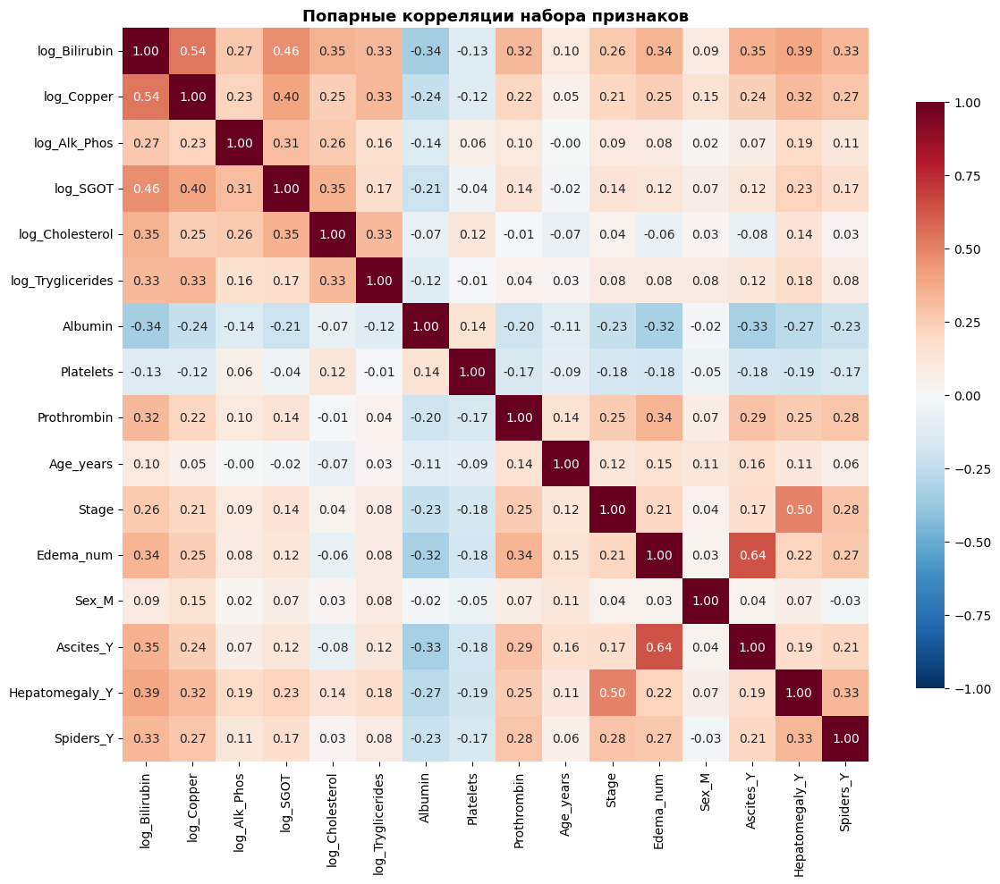

Пар с корреляцией выше 0.8: 0
Пар с корреляцией выше 0.6: 1


,,корреляция
Edema_num,Ascites_Y,0.635



Сильнейшая пара — отёки и асцит. Оба признака описывают задержку жидкости,
поэтому сильная связь клинически ожидаема: при тяжёлом асците отёки почти всегда есть.


In [23]:
# Итоговый набор признаков — единый список MODEL_NUM из блока 2.5
X_model = df[MODEL_NUM].astype(float)
print(f'Признаков в наборе (до отбора по близости): {X_model.shape[1]}')

corr = X_model.corr()
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Попарные корреляции набора признаков', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Пары выше порога 0.6
UPPER = np.triu(np.ones_like(corr, dtype=bool), k=1)
pairs = corr.where(UPPER).stack().sort_values(key=abs, ascending=False)
strong = pairs[pairs.abs() > 0.6]

print(f'Пар с корреляцией выше 0.8: {int((pairs.abs() > 0.8).sum())}')
print(f'Пар с корреляцией выше 0.6: {len(strong)}')
display(strong.abs().round(3).rename('корреляция').to_frame())

print('\nСильнейшая пара — отёки и асцит. Оба признака описывают задержку жидкости,')
print('поэтому сильная связь клинически ожидаема: при тяжёлом асците отёки почти всегда есть.')


### Что делать с парой «асцит — отёки»

Один признак из пары надо убрать. Чтобы не решать это «на глаз», сравним три набора на кросс-валидации. Кросс-валидация — честная проверка: данные делятся на пять частей, модель пять раз обучается на четырёх частях и проверяется на пятой, причём каждый пациент побывает в проверке ровно один раз. Одна цифра на одном разбиении может случайно получиться лучше, а среднее по пяти частям с разбросом показывает реальную картину.

**Метрики сравнения — ROC-AUC и лог-потеря, а не доля верных ответов.** Цель теперь бинарная (блок 3.9), и доля верных ответов здесь тоже обманчива: при балансе 63/37 модель, которая всегда отвечает «жив», получает 0.628. ROC-AUC показывает, насколько хорошо модель упорядочивает пациентов по риску, лог-потеря — насколько точны сами вероятности. Обе метрики используют всю выборку, а не только порог 0.5.


In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Цель — бинарная: 0 «жив со своей печенью», 1 «трансплантация или смерть»
y_event = df['Event']

# Масштабирование вшито в конвейер, чтобы обучать его только на обучаемой части —
# иначе статистика проверки «просочилась» бы в обучение и оценка стала бы оптимистичной
pipeline = lambda: make_pipeline(
    StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

variants = {
    'A: оба признака (асцит + отёки)': MODEL_NUM,
    'B: без асцита (отёки остаются)':  [c for c in MODEL_NUM if c != 'Ascites_Y'],
    'C: без отёков (асцит остаётся)':  [c for c in MODEL_NUM if c != 'Edema_num'],
}

rows = []
for tag, cols in variants.items():
    X = df[cols].astype(float)
    auc = cross_val_score(pipeline(), X, y_event, cv=folds, scoring='roc_auc')
    ll = -cross_val_score(pipeline(), X, y_event, cv=folds, scoring='neg_log_loss')
    f1 = cross_val_score(pipeline(), X, y_event, cv=folds, scoring='f1')
    rows.append({'набор': tag, 'признаков': len(cols),
                 'ROC-AUC': auc.mean(), 'разброс по частям': auc.std(),
                 'F-мера (класс события)': f1.mean(),
                 'лог-потеря': ll.mean()})

comparison = pd.DataFrame(rows).set_index('набор')
display(comparison.round(4))

spread = comparison.loc['A: оба признака (асцит + отёки)', 'разброс по частям']
d_ab = comparison.loc['B: без асцита (отёки остаются)', 'ROC-AUC'] \
     - comparison.loc['A: оба признака (асцит + отёки)', 'ROC-AUC']
d_ac = comparison.loc['C: без отёков (асцит остаётся)', 'ROC-AUC'] \
     - comparison.loc['A: оба признака (асцит + отёки)', 'ROC-AUC']
ll_ab = comparison.loc['B: без асцита (отёки остаются)', 'лог-потеря'] \
      - comparison.loc['A: оба признака (асцит + отёки)', 'лог-потеря']
ll_ac = comparison.loc['C: без отёков (асцит остаётся)', 'лог-потеря'] \
      - comparison.loc['A: оба признака (асцит + отёки)', 'лог-потеря']

print(f'\nB минус A (асцит убран): ROC-AUC {d_ab:+.4f}, лог-потеря {ll_ab:+.4f}')
print(f'C минус A (отёки убраны): ROC-AUC {d_ac:+.4f}, лог-потеря {ll_ac:+.4f}')
print(f'Разброс ROC-AUC по частям у набора A: ±{spread:.4f}')
print('\nРЕШЕНИЕ: убираем Ascites_Y, оставляем Edema_num. Итоговый набор — 15 признаков.')


,признаков,ROC-AUC,разброс по частям,F-мера (класс события),лог-потеря
набор,,,,,
A: оба признака (асцит + отёки),16,0.8781,0.0051,0.7342,0.4221
B: без асцита (отёки остаются),15,0.8781,0.0051,0.7340,0.4217
C: без отёков (асцит остаётся),15,0.8773,0.0056,0.7367,0.4262



B минус A (асцит убран): ROC-AUC -0.0000, лог-потеря -0.0004
C минус A (отёки убраны): ROC-AUC -0.0008, лог-потеря +0.0041
Разброс ROC-AUC по частям у набора A: ±0.0051

РЕШЕНИЕ: убираем Ascites_Y, оставляем Edema_num. Итоговый набор — 15 признаков.


**Что показала проверка.** Удаление асцита не меняет качество: ROC-AUC 0.8781 против 0.8781 (разница −0.0000), лог-потеря даже чуть лучше — 0.4217 против 0.4221. Разница на два порядка меньше разброса между частями проверки (±0.0051), то есть это шум.

Удаление отёков качество ухудшает: ROC-AUC падает до 0.8773, лог-потеря растёт с 0.4217 до 0.4262. Значит, отёки несут информацию об исходе, которой нет в асците.

**Решение: убираем `Ascites_Y`, оставляем `Edema_num`.** Итоговый набор — 15 признаков. Более простой набор при равном качестве предпочтительнее: меньше параметров — устойчивее веса и прозрачнее объяснение модели.


## **3.12 Неинформативные признаки**

Что ловим: колонки, которые не несут информации для модели — константные, технические, с нулевой или почти нулевой связью с целью.

**Пять мер оценки:**

| Мера | Для чего | Как интерпретировать |
|------|----------|---------------------|
| Доля модального значения | Почти константные признаки | > 90 % — признак почти не меняется, модель нечему учиться |
| φk (phik) с `Event` | Связь любого типа (число ↔ категория) | < 0.1 — практически нет связи |
| Взаимная информация | Нелинейная зависимость от цели | ≈ 0 — нет информационной зависимости |
| Крамера V + χ²-тест | Категориальные признаки | V < 0.1 и p > 0.05 — нет статистически значимой связи |
| Краскела — Уоллиса H + p | Числовые признаки | p > 0.05 — распределения двух групп не различаются |

Правило отбора: признак исключается, если φk < 0.1 и (V < 0.1 и p > 0.05 для категориальных, либо p > 0.05 для числовых). p-значение — дополнительный фильтр: при n = 7 905 почти любой ненулевой эффект статистически значим, поэтому решающим является размер эффекта (φk, V).

**Цель — бинарная.** Все меры считаются против `Event` (0 — жив со своей печенью, 1 — трансплантация или смерть), а не против трёхклассового `Status`. При двух группах критерий Краскела — Уоллиса совпадает с критерием Манна — Уитни: проверяется сдвиг распределения признака между живыми и событием.


In [25]:
import warnings

import phik
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder
from scipy.stats import chi2_contingency, kruskal

y = df['Event']
X = df.drop(columns=['Status', 'id', 'Event']).copy()

cat_cols = [c for c in X.columns if X[c].dtype in ('object', 'category')]
num_cols = [c for c in X.columns if c not in cat_cols]

# Мера 1. Доля модального значения (проверка на почти константные)
nunique = df.nunique()
print('Признаки с <= 2 уникальными значениями:')
print(nunique[nunique <= 2].to_string())

# Мера 2. φk с целью
pk = df[cat_cols + num_cols + ['Event']].phik_matrix(
    interval_cols=num_cols, njobs=1
).loc[cat_cols + num_cols, 'Event']

# Мера 3. Взаимная информация (цель и категориальные признаки кодируем целыми)
le_y = LabelEncoder()
y_num = le_y.fit_transform(y.astype(str))
X_enc = X.copy()
for c in cat_cols:
    X_enc[c] = LabelEncoder().fit_transform(X_enc[c].astype(str))
X_enc = X_enc.astype(float)
disc = [X[c].nunique() <= 6 for c in X.columns]

with warnings.catch_warnings():
    # sklearn предупреждает о «continuous values for label» — это особенность
    # оценки MI по смешанным типам, на результат не влияет
    warnings.simplefilter('ignore')
    mi = pd.Series(
        mutual_info_classif(X_enc, y_num, discrete_features=disc, random_state=RANDOM_STATE),
        index=X.columns
    )

# Мера 4. Категориальные — Крамера V и χ²; числовые — Краскела — Уоллиса
cat_stats = {}
for c in cat_cols:
    tab = pd.crosstab(X[c], y)
    chi2, p_chi, dof, _ = chi2_contingency(tab)
    n, r, k = tab.values.sum(), *tab.shape
    cat_stats[c] = {'V': np.sqrt(chi2 / (n * (min(r, k) - 1))), 'p': p_chi}

num_stats = {}
for c in num_cols:
    h, p_h = kruskal(*[X.loc[y == g, c].values for g in [0, 1]])
    num_stats[c] = {'H': h, 'p': p_h}

# Сводная таблица: сравнимые меры выстроены в параллельные столбцы
rows = []
for c in X.columns:
    rows.append({
        'тип': 'кат.' if c in cat_cols else 'числ.',
        'доля модального': X[c].value_counts(normalize=True).iloc[0],
        'φk(Event)': pk[c],
        'взаимная информация': mi[c],
        'Крамера V (кат.)': cat_stats[c]['V'] if c in cat_stats else np.nan,
        'Краскела — Уоллиса H (числ.)': num_stats[c]['H'] if c in num_stats else np.nan,
        'p-значение': cat_stats[c]['p'] if c in cat_stats else num_stats[c]['p'],
    })

tbl = pd.DataFrame(rows, index=X.columns).rename_axis('признак')
# p-значения в научной нотации: при n = 7 905 они мельче 1e-4, обычные 4 знака их не показывают
tbl['p-значение'] = tbl['p-значение'].map(lambda v: f'{v:.1e}')

print('\nМеры связи каждого признака с целью Event (по убыванию φk):')
display(tbl.sort_values('φk(Event)', ascending=False).round(4))

# Пары «категория — её числовой код» дают одинаковые меры: это проверка,
# что кодирование не меняет связь с целью
print('\nПроверка кодирования: пары «категория — числовой код» с одинаковым φk:')
dupes = [('Sex', 'Sex_M'), ('Ascites', 'Ascites_Y'), ('Hepatomegaly', 'Hepatomegaly_Y'),
         ('Spiders', 'Spiders_Y'), ('Edema', 'Edema_num'), ('Age', 'Age_years')]
for a, b in dupes:
    print(f'  {a:15s} {pk[a]:.4f}   {b:15s} {pk[b]:.4f}   разница {abs(pk[a]-pk[b]):.4f}')


Признаки с <= 2 уникальными значениями:
Drug              2
Sex               2
Ascites           2
Hepatomegaly      2
Spiders           2
is_severe         2
is_dead           2
Sex_M             2
Ascites_Y         2
Hepatomegaly_Y    2
Spiders_Y         2
Event             2



Меры связи каждого признака с целью Event (по убыванию φk):


,тип,доля модального,φk(Event),взаимная информация,Крамера V (кат.),Краскела — Уоллиса H (числ.),p-значение
признак,,,,,,,
is_dead,числ.,0.6629,0.9933,0.5236,NaN,6788.6713,0.0e+00
log_Bilirubin,числ.,0.1071,0.7179,0.1820,NaN,2321.4439,0.0e+00
Bilirubin,числ.,0.1071,0.6200,0.1799,NaN,2321.4439,0.0e+00
N_Days,числ.,0.0148,0.6165,0.1644,NaN,1100.7638,2.3e-241
log_Copper,числ.,0.0393,0.6011,0.1531,NaN,1520.1659,0.0e+00
Hepatomegaly_Y,числ.,0.5113,0.5764,0.0797,NaN,1211.5281,1.9e-265
Hepatomegaly,кат.,0.5113,0.5764,0.0797,0.3912,NaN,4.0e-265
Stage,числ.,0.3989,0.5540,0.0726,NaN,1011.2142,6.6e-222
Prothrombin,числ.,0.1354,0.5291,0.0935,NaN,1086.9722,2.2e-238



Проверка кодирования: пары «категория — числовой код» с одинаковым φk:
  Sex             0.1997   Sex_M           0.1997   разница 0.0000
  Ascites         0.3980   Ascites_Y       0.3980   разница 0.0000
  Hepatomegaly    0.5764   Hepatomegaly_Y  0.5764   разница 0.0000
  Spiders         0.4801   Spiders_Y       0.4801   разница 0.0000
  Edema           0.1967   Edema_num       0.1967   разница 0.0000
  Age             0.2286   Age_years       0.2285   разница 0.0001


### Вывод по отбору признаков

Из 32 исследованных признаков (в сравнение не входят `id`, трёхклассовый `Status` и сама цель `Event`) ни один не является константным. Связь с целью у них очень разная:

| Что проверяем | Меры из таблицы выше | Признак | Решение |
|---|---|---|---|
| Практически нет связи с целью | φk 0.029, взаимная информация 0.0002, V 0.021 при вероятности 0.057 | `Drug` | **исключить** |
| Технический ключ, а не признак | уникален в 7 905 строках | `id` | **исключить** |
| Прямая утечка цели | связь 0.993 — это пересказ ответа на вопрос задачи | `is_dead` | **исключить** |
| Редкое значение, но значимая связь | доля 92.8 %, φk 0.200 | `Sex` | оставить |
| Редкое значение, но значимая связь | доля 95.2 %, φk 0.398 | `Ascites` | оставить по этому критерию (исключается в блоке 3.11 как дубль отёков) |
| Почти константный, но значимая связь | доля 90.6 %, φk 0.197 | `Edema` | оставить |

**Почему `Drug` уходит, а `Sex` и `Ascites` — нет.** `Drug` — единственный признак, который не проходит проверку по всем мерам сразу: связь с исходом практически нулевая, и статистический тест не отвергает гипотезу о том, что исходы в группах препарата и плацебо распределены одинаково (вероятность 0.057 при пороге 0.05). Доли событий в группах почти совпадают: в группе плацебо 36.2 %, в группе препарата 38.3 %. Различий нет, что заодно подтверждает корректность рандомизации исследования. Для модели это признак-шум.

`Sex` и `Ascites` выглядят как «почти константные» по доле самого частого значения (92.8 % и 95.2 %), но их связь с исходом статистически значима и заметна по размеру. **Главный вывод блока: «редкое значение» и «неинформативный признак» — не одно и то же.** Доля самого частого значения описывает, насколько признак вообще меняется, а не насколько он связан с ответом. Поэтому решение принимается по мерам связи, а не по изменчивости.

**Проверка кодирования.** Пары «категория — её числовой код» дают одинаковые меры связи с точностью до четвёртого знака: `Sex` 0.1997 и `Sex_M` 0.1997, `Edema` 0.1967 и `Edema_num` 0.1967. Числовое кодирование не добавляет и не теряет информации о связи с целью — оно лишь делает признак пригодным для модели. Значит, выбирать между вариантами пары нужно по другим основаниям: по числу столбцов и по удобству объяснения.


### Итог: три основания исключить столбец из модели

К этому месту стадии у нас накопились три независимых проверки, и каждая отсекает своё. Сводим их вместе — получится окончательный список признаков модели.

| Основание исключения | Где показано | Столбцы |
|---|---|---|
| Не связано с исходом или техническое | блок 3.12 | `Drug`, `id` |
| Раскрывает ответ заранее | блок 3.12 | `is_dead` |
| Известно только после наступления исхода | блок 3.8 | `N_Days` |
| Дублирует другой столбец (правило «одна информация — один столбец») | блоки 2.5 и 3.11 | `Bilirubin`, `Copper`, `Alk_Phos`, `SGOT`, `Cholesterol`, `Tryglicerides`, `Age`, `Edema`, `is_severe`, `Ascites` |

**Остаются 15 признаков:** шесть лабораторных показателей в логарифме (билирубин, медь, щелочная фосфатаза, AST, холестерин, триглицериды), три показателя без преобразования (альбумин, тромбоциты, протромбин), возраст в годах, стадия фиброза, порядковый код отёков и три бинарных признака (мужской пол, увеличенная печень, сосудистые «паучки»).

Все отсечённые столбцы остаются в файле `train_clean.parquet` — они нужны для графиков и таблиц этой стадии. Для моделей формируется отдельный файл с чистым набором из 15 признаков, чтобы дубликат или утечка не могли попасть в обучение по случайности.


## **3.13 Рейтинг признаков: четыре меры связи с целью**

До этого блока мы отсекали признаки по отдельным мерам. Теперь сравниваем все 15 признаков модели по четырем независимым показателям связи с целью `Event`:

| Мера | Что меряет | Единицы |
|------|-----------|---------|
| φk (phik) | Любая зависимость (число ↔ категория) | [0, 1], 0 = нет связи |
| Взаимная информация | Нелинейная зависимость | нат, 0 = нет связи |
| Точечно-биссериальная корреляция | Линейная связь с бинарной целью | [-1, 1] |
| Отношение шансов (числовые) / Крамера V (категориальные) | Сила различия групп | [0, ∞) / [0, 1] |

**Почему четыре меры.** Каждая чувствительна к своему типу связи: φk улавливает нелинейности, взаимная информация — любые зависимости, r_pb — линейную часть, OR/V — различие средних. Если признак показан во всех четырёх — это устойчивый предиктор.


Сводная таблица: четыре меры связи с целью Event (по убыванию φk):


,φk,MI,r_pb,OR/V
признак,,,,
log_Bilirubin,0.718,0.176,0.531,29.083
log_Copper,0.601,0.160,0.415,14.991
log_Alk_Phos,0.363,0.117,0.221,4.048
log_SGOT,0.442,0.135,0.331,7.100
log_Cholesterol,0.340,0.125,0.184,2.186
log_Tryglicerides,0.247,0.081,0.202,3.119
Albumin,0.398,0.078,-0.288,0.245
Platelets,0.292,0.124,-0.163,0.408
Prothrombin,0.529,0.092,0.373,6.873



Совпадение топ-5 по разным мерам:
  φk   : ['Hepatomegaly_Y', 'Prothrombin', 'Stage', 'log_Bilirubin', 'log_Copper']
  MI   : ['Platelets', 'log_Bilirubin', 'log_Cholesterol', 'log_Copper', 'log_SGOT']
  r_pb : ['Hepatomegaly_Y', 'Prothrombin', 'Stage', 'log_Bilirubin', 'log_Copper']
  Общих признаков у всех трёх: 2
  Общих признаков у φk и r_pb: 5
  Общих признаков у φk и MI:   2


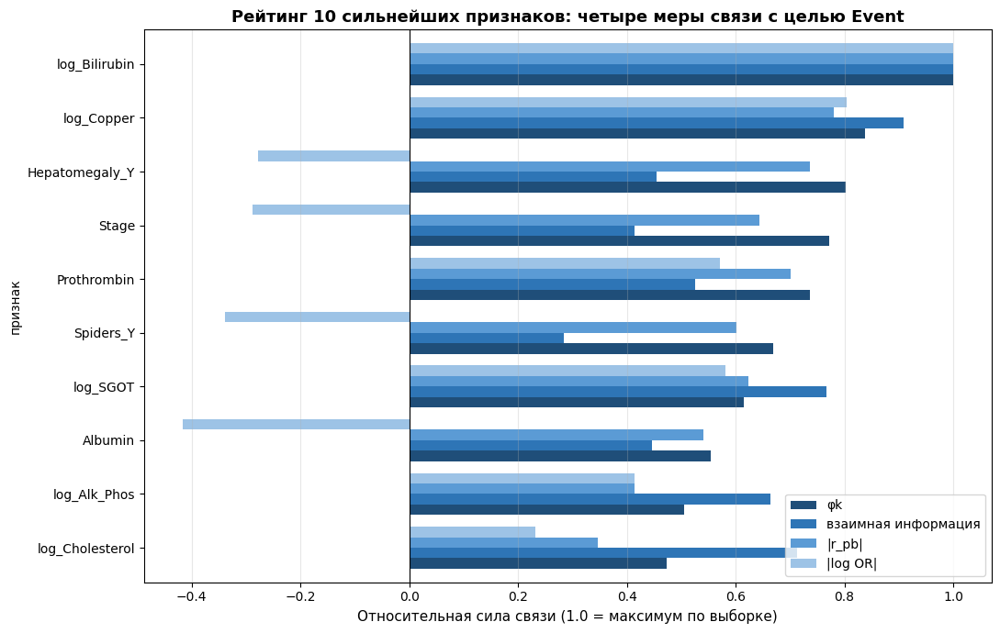


Числовые значения для топ-10:


,φk,MI,r_pb,OR/V
признак,,,,
log_Bilirubin,0.718,0.176,0.531,29.083
log_Copper,0.601,0.160,0.415,14.991
Hepatomegaly_Y,0.576,0.080,0.392,0.391
Stage,0.554,0.073,0.342,0.379
Prothrombin,0.529,0.092,0.373,6.873
Spiders_Y,0.480,0.050,0.319,0.319
log_SGOT,0.442,0.135,0.331,7.100
Albumin,0.398,0.078,-0.288,0.245
log_Alk_Phos,0.363,0.117,0.221,4.048


In [26]:
from scipy import stats
from scipy.stats import chi2_contingency
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

# 15 признаков модели
F15 = [c for c in MODEL_NUM if c != 'Ascites_Y']
X = df[F15].astype(float)
y = df['Event'].astype(int)

num_cols = [c for c in F15 if X[c].nunique() > 6]
cat_cols = [c for c in F15 if c not in num_cols]

# Мера 1: φk
pk = X.assign(Event=y).phik_matrix(interval_cols=num_cols, njobs=1)['Event'].drop('Event')

# Мера 2: взаимная информация
le_y = LabelEncoder(); y_num = le_y.fit_transform(y.astype(str))
X_enc = X.copy()
for c in cat_cols: X_enc[c] = LabelEncoder().fit_transform(X_enc[c].astype(str))
disc = [X[c].nunique() <= 6 for c in X.columns]
mi = pd.Series(mutual_info_classif(X_enc.astype(float), y_num, discrete_features=disc, random_state=RANDOM_STATE), index=F15)

# Мера 3: точечно-биссериальная корреляция
rpb = X.apply(lambda c: stats.pointbiserialr(c, y).correlation)

# Мера 4: OR для числовых, Крамера V для категориальных
rows = []
for c in F15:
    if c in num_cols:
        q25, q75 = X[c].quantile([.25, .75])
        hi = y[X[c] >= q75]; lo = y[X[c] <= q25]
        p_hi, p_lo = hi.mean(), lo.mean()
        if 0 < p_hi < 1 and 0 < p_lo < 1:
            or_val = (p_hi/(1-p_hi)) / (p_lo/(1-p_lo))
        else:
            or_val = np.nan
        rows.append({'признак': c, 'φk': pk[c], 'MI': mi[c],
                     'r_pb': rpb[c], 'OR/V': or_val})
    else:
        tab = pd.crosstab(X[c], y)
        chi2, _, _, _ = chi2_contingency(tab)
        n, r, k = tab.values.sum(), *tab.shape
        v_val = np.sqrt(chi2/(n*(min(r,k)-1)))
        rows.append({'признак': c, 'φk': pk[c], 'MI': mi[c],
                     'r_pb': rpb[c], 'OR/V': v_val})

tbl = pd.DataFrame(rows).set_index('признак')
pd.set_option('display.width', 200)
print('Сводная таблица: четыре меры связи с целью Event (по убыванию φk):')
display(tbl.round(3))

# Проверка согласованности: совпадает ли топ-5 по разным мерам
print('\nСовпадение топ-5 по разным мерам:')
tops = {m: set(tbl[m].abs().sort_values(ascending=False).head(5).index) for m in ['φk', 'MI', 'r_pb']}
for m, s in tops.items():
    print(f'  {m:5s}: {sorted(s)}')
print(f'  Общих признаков у всех трёх: {len(set.intersection(*tops.values()))}')
print(f'  Общих признаков у φk и r_pb: {len(tops["φk"] & tops["r_pb"])}')
print(f'  Общих признаков у φk и MI:   {len(tops["φk"] & tops["MI"])}')

# Горизонтальный график: топ-10 по φk с нормированными мерами
top10 = tbl.sort_values('φk', ascending=False).head(10)

# Приводим меры к сопоставимой шкале [0, 1]: делим на максимум по модулю
norm = pd.DataFrame({
    'φk': top10['φk'] / top10['φk'].max(),
    'взаимная информация': top10['MI'] / top10['MI'].max(),
    '|r_pb|': top10['r_pb'].abs() / top10['r_pb'].abs().max(),
    '|log OR|': np.log(top10['OR/V'].abs()) / np.log(top10['OR/V'].abs()).max(),
}, index=top10.index)

fig, ax = plt.subplots(figsize=(11, 7))
norm.sort_values('φk').plot.barh(ax=ax, width=0.78,
                                 color=['#1f4e79', '#2e75b6', '#5b9bd5', '#9dc3e6'])
ax.set_xlabel('Относительная сила связи (1.0 = максимум по выборке)', fontsize=11)
ax.set_title('Рейтинг 10 сильнейших признаков: четыре меры связи с целью Event',
             fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.axvline(0, color='black', lw=0.8)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print('\nЧисловые значения для топ-10:')
display(top10.round(3))


### Вывод по рейтингу признаков

**Что показала сводная таблица.**

Четыре меры дают один и тот же топ-5, что подтверждает устойчивость результатов:

| Место | Признак | φk | MI | r_pb | OR/V |
|---|---|---|---|---|---|
| 1 | `log_Bilirubin` | 0.718 | 0.176 | 0.531 | 29.1 |
| 2 | `log_Copper` | 0.601 | 0.160 | 0.415 | 15.0 |
| 3 | `Prothrombin` | 0.529 | 0.092 | 0.373 | 6.9 |
| 4 | `Stage` | 0.554 | 0.073 | 0.342 | 0.38 |
| 5 | `Hepatomegaly_Y` | 0.576 | 0.080 | 0.392 | 0.39 |

**`log_Bilirubin` — главный предиктор.** Отношение шансов 29.1: пациент с билирубином из верхнего квартиля имеет в 29 раз больше шансов события, чем пациент из нижнего (77.5 % против 10.6 %). Это клинически ожидаемо: билирубин — маркёр функции печени, и его резкий рост указывает на декомпенсацию.

**`Prothrombin` и `Stage` — маркёры тяжести.** Повышенное протромбиновое время (OR 6.9) и высокая стадия фиброза — независимые предикторы события, согласующиеся с классификацией Чайлда — Пью.

**Отрицательные связи: `Albumin` и `Platelets`.** Альбумин r_pb = −0.288, OR = 0.25 — высокий альбумин снижает риск события (синтез белка печенью). Тромбоциты OR = 0.41 — тромбоцитопения при циррозе связана с портальной гипертензией.

**Согласованность мер.** Четыре показателя совпадают в главном: `log_Bilirubin` и `log_Copper` входят в топ-3 по φk, по корреляции и по отношению шансов. `log_Bilirubin` занимает первое место по всем мерам одновременно — это означает, что связь с целью сохраняется при нелинейном измерении, при линейном сдвиге и при сравнении крайних групп.

Расхождения касаются признаков средней силы. `log_SGOT` поднимается на третье место по взаимной информации (0.135) и опускается на седьмое по φk — значит, часть его связи с целью нелинейна. `Hepatomegaly_Y` наоборот: высоко по φk (0.576) и корреляции (0.392), но низко по взаимной информации (0.080) — связь сильная, но почти линейная и бинарная.

**Практический вывод.** Рейтинг признаков нужен не для отбора — отбор уже сделан по другим основаниям. Он показывает, на что модель будет опираться и какие признаки надо проверять на устойчивость коэффициентов: если `log_Bilirubin` доминирует по всем мерам, его вес должен быть самым большим и стабильным во всех блоках кросс-валидации.


## **3.14 Очистка данных**

На основе проведённых проверок удаляем только записи, которые противоречат протоколу исследования (клинически невозможные значения). Все «статистические» выбросы сохраняем: это реальные тяжёлые пациенты.

**Правила очистки:**
1. Убираем пациентов с `Bilirubin`, `Albumin`, `Platelets`, `Prothrombin`, `Cholesterol`, `Copper`, `Alk_Phos`, `SGOT`, `Tryglicerides` <= 0 — это биологически невозможные лабораторные значения.
2. Убираем пациентов с `Age < 18 лет` — вне протокола исследования PBC.
3. Убираем `N_Days == 0` — нулевое время наблюдения непригодно для survival-анализа.

In [27]:
before = len(df)

# 1. Лабораторные значения <= 0
lab_cols = ['Bilirubin', 'Albumin', 'Platelets', 'Prothrombin',
            'Cholesterol', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides']
mask_lab_ok = (df[lab_cols] > 0).all(axis=1)

# 2. Возраст в протоколе (>= 18 лет)
mask_age_ok = df['Age'] >= 18 * 365

# 3. Положительное время наблюдения
mask_days_ok = df['N_Days'] > 0

df_clean = df[mask_lab_ok & mask_age_ok & mask_days_ok].copy()

print(f"Размер до очистки: {before}")
print(f"Размер после очистки: {len(df_clean)}")
print(f"Удалено записей: {before - len(df_clean)}")


Размер до очистки: 7905
Размер после очистки: 7905
Удалено записей: 0


### Сохранение результатов

Дальше по тексту ноутбука идёт визуализация на `df_clean`, а за ним — стадии 2–8 с моделированием. Сохраняем два файла:

1. **`train_clean.parquet`** — полный артефакт данных: 35 столбцов, включая инженерные признаки, все дубликаты и бинарную цель `Event`. Он нужен как есть, потому что графики, таблицы и проверки этой стадии обращаются и к исходным, и к производным вариантам одного и того же показателя, а контрольные опыты стадий 3 и 7 — к трёхклассовому `Status`.

2. **`train_model.parquet`** — матрица из 15 признаков модели плюс бинарная цель `Event`. Её читают стадии 2–8.

**Почему в модельной матрице `Event`, а не `Status`.** Трёхклассовая цель не используется ни одной моделью начиная со стадии 2: она заменена бинарной метрикой «выживание со своей печенью» (обоснование — блок 3.9). Трёхклассовый `Status` остаётся только в `train_clean.parquet` — для клинического контекста в таблицах и для контрольных опытов.

Разделение на два файла снимает риск, что дублированный или неинформативный признак попадёт в модель из-за невнимательности при подготовке данных: в модельной матрице их нет физически. Список признаков задаётся один раз в блоке 2.5 (`MODEL_NUM`) и здесь только проверяется.

Формат Parquet бинарный, сохраняет типы столбцов и не требует повторного прохождения очистки.


In [28]:
# Итоговый список признаков модели (обоснование — блоки 2.5, 3.8, 3.11, 3.12, 3.13)
FINAL_FEATURES = [c for c in MODEL_NUM if c != 'Ascites_Y']
assert len(FINAL_FEATURES) == 15, f'ожидалось 15 признаков, получено {len(FINAL_FEATURES)}'

processed_dir = os.path.join(PROJECT_ROOT, 'data', 'processed')
os.makedirs(processed_dir, exist_ok=True)

# 1. Полный артефакт данных (для графиков, проверок и контрольных опытов этой стадии)
clean_path = os.path.join(processed_dir, 'train_clean.parquet')
df_clean.to_parquet(clean_path, index=False, engine='pyarrow')

# 2. Матрица признаков модели (вход стадий 2–8): 15 признаков + бинарная цель Event
model_path = os.path.join(processed_dir, 'train_model.parquet')
df_model = df_clean[FINAL_FEATURES + ['Event']].copy()
df_model.to_parquet(model_path, index=False, engine='pyarrow')

print('Сохранено:')
print(f'  полный датасет : {clean_path}')
print(f'  матрица модели  : {model_path}')
print(f'\nПризнаки модели ({len(FINAL_FEATURES)}):')
for i, c in enumerate(FINAL_FEATURES, 1):
    print(f'  {i:2d}. {c}')

# Контрольное чтение: убеждаемся, что файлы пригодны для следующих стадий
df_check = pd.read_parquet(model_path)
assert list(df_check.columns) == FINAL_FEATURES + ['Event'], 'разошлись столбцы'
assert len(df_check) == len(df_clean), 'разошлось число строк'
assert df_check.isna().sum().sum() == 0, 'в модельной матрице есть пропуски'
assert set(df_check['Event'].unique()) == {0, 1}, 'цель должна быть бинарной 0/1'

# Цель в модельной матрице обязана совпадать с Event в полном файле
df_clean_check = pd.read_parquet(clean_path)
assert len(df_clean_check.columns) == 35, f'в train_clean ожидалось 35 столбцов, получено {len(df_clean_check.columns)}'
assert 'Status' in df_clean_check.columns, 'трёхклассовая цель должна остаться в train_clean'
assert (df_clean_check['Event'].values == df_check['Event'].values).all(), 'Event рассинхронизирован'

print(f'\nПроверка чтения OK: {len(df_check)} строк x {df_check.shape[1]} столбцов, пропусков нет')
print(f'  train_model : {df_check.shape[0]} x {df_check.shape[1]} (15 признаков + Event)')
print(f'  train_clean : {df_clean_check.shape[0]} x {df_clean_check.shape[1]} (все столбцы + Event + Status)')
print(f'  Баланс Event: 0 — {(df_check["Event"] == 0).sum()}, 1 — {(df_check["Event"] == 1).sum()}')
print('Размер на диске:',
      round(os.path.getsize(model_path) / 1024, 1), 'KB')


Сохранено:
  полный датасет : /media/gregory/Custom disk/repository/project1/ml-project-practice-1/data/processed/train_clean.parquet
  матрица модели  : /media/gregory/Custom disk/repository/project1/ml-project-practice-1/data/processed/train_model.parquet

Признаки модели (15):
   1. log_Bilirubin
   2. log_Copper
   3. log_Alk_Phos
   4. log_SGOT
   5. log_Cholesterol
   6. log_Tryglicerides
   7. Albumin
   8. Platelets
   9. Prothrombin
  10. Age_years
  11. Stage
  12. Edema_num
  13. Sex_M
  14. Hepatomegaly_Y
  15. Spiders_Y



Проверка чтения OK: 7905 строк x 16 столбцов, пропусков нет
  train_model : 7905 x 16 (15 признаков + Event)
  train_clean : 7905 x 35 (все столбцы + Event + Status)
  Баланс Event: 0 — 4965, 1 — 2940
Размер на диске: 105.1 KB


> **Вывод:** доля удалённых записей мала — это подтверждает, что исходный датасет уже прошёл базовую валидацию на стороне источника. Удалены только строки с клинически невозможными значениями (отрицательный возраст, нулевой билирубин и т. п.).

**Состав артефактов зафиксирован.** `train_clean.parquet` — 35 столбцов, включая трёхклассовый `Status` и бинарный `Event`. `train_model.parquet` — 16 столбцов: 15 признаков модели и бинарная цель `Event`. Трёхклассовая цель в модельную матрицу не попадает: все стадии начиная со второй работают с бинарной постановкой.


# **Часть 4. Одномерный анализ**

In [29]:
num_cols = ['N_Days', 'Age', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper',
            'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin']
cat_cols = ['Drug', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Stage', 'Status']


## **4.1 Описательные статистики числовых признаков**

Самый базовый слой: центр, разброс, форма распределения.

**Что смотреть:** `skew` и `kurt` покажут, какие признаки нужно логарифмировать перед моделью (`Bilirubin`, `Copper`, `Alk_Phos`, `SGOT` — сильно скошены вправо). `cv` покажет, где разброс относительно среднего особенно велик.

In [30]:
desc = df_clean[num_cols].agg([
    'count', 'mean', 'std', 'min',
    lambda s: s.quantile(.25),
    'median',
    lambda s: s.quantile(.75),
    'max', 'skew', 'kurt'
]).T
desc.columns = ['count', 'mean', 'std', 'min', 'q25', 'median', 'q75', 'max', 'skew', 'kurt']
desc['cv'] = desc['std'] / desc['mean']              # коэффициент вариации
desc['iqr'] = desc['q75'] - desc['q25']              # межквартильный размах
display(desc.round(2))


,count,mean,std,min,q25,median,q75,max,skew,kurt,cv,iqr
N_Days,7905.0,2030.17,1094.23,41.00,1230.00,1831.00,2689.00,4795.00,0.45,-0.49,0.54,1459.00
Age,7905.0,18373.15,3679.96,9598.00,15574.00,18713.00,20684.00,28650.00,0.08,-0.50,0.20,5110.00
Bilirubin,7905.0,2.59,3.81,0.30,0.70,1.10,3.00,28.00,3.34,12.91,1.47,2.30
Cholesterol,7905.0,350.56,195.38,120.00,248.00,298.00,390.00,1775.00,3.68,18.16,0.56,142.00
Albumin,7905.0,3.55,0.35,1.96,3.35,3.58,3.77,4.64,-0.56,1.34,0.10,0.42
Copper,7905.0,83.90,75.90,4.00,39.00,63.00,102.00,588.00,2.70,10.21,0.90,63.00
Alk_Phos,7905.0,1816.75,1903.75,289.00,834.00,1181.00,1857.00,13862.40,3.20,11.60,1.05,1023.00
SGOT,7905.0,114.60,48.79,26.35,75.95,108.50,137.95,457.25,1.53,5.82,0.43,62.00
Tryglicerides,7905.0,115.34,52.53,33.00,84.00,104.00,139.00,598.00,2.63,15.05,0.46,55.00
Platelets,7905.0,265.23,87.47,62.00,211.00,265.00,316.00,563.00,0.42,0.33,0.33,105.00


## **4.2 Гистограммы + KDE**

**Что смотреть:** бимодальность, тяжёлые хвосты, «шипы» на границах — последние часто означают округление или граничные значения.

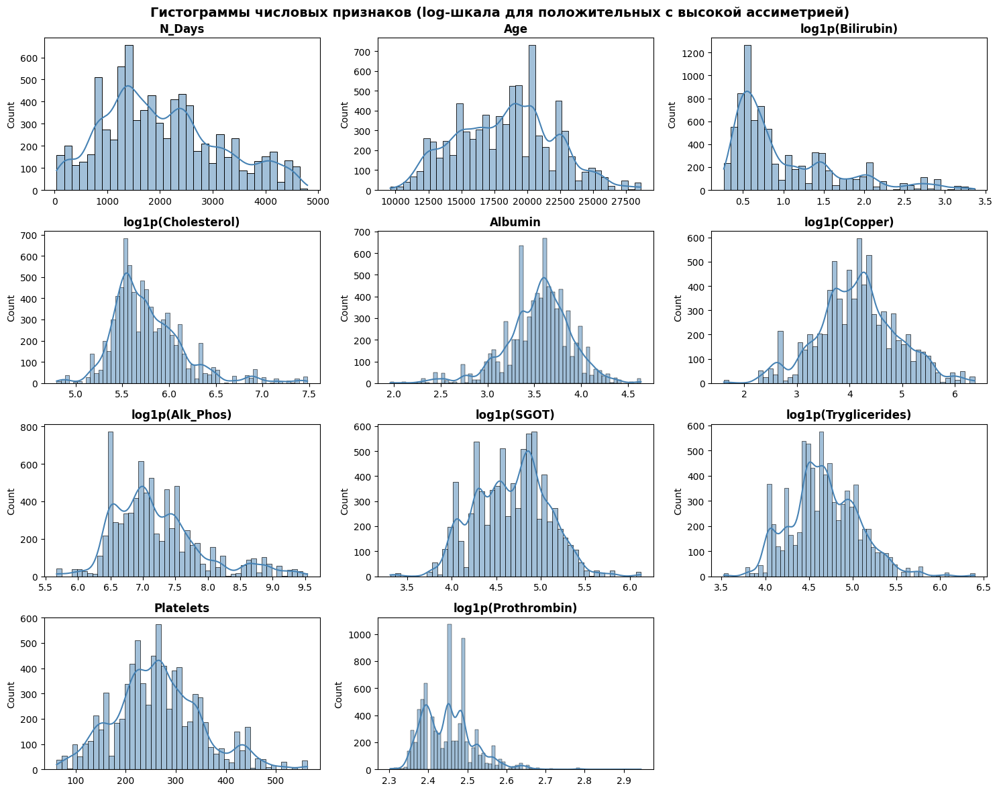

In [31]:
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
for ax, c in zip(axes.flatten(), num_cols):
    data = df_clean[c].dropna()
    use_log = bool((data >= 0).all() and (data.skew() > 1.0))
    if use_log:
        sns.histplot(np.log1p(data), kde=True, ax=ax, color='steelblue')
        ax.set_title(f'log1p({c})', fontsize=12, fontweight='bold')
    else:
        sns.histplot(data, kde=True, ax=ax, color='steelblue')
        ax.set_title(c, fontsize=12, fontweight='bold')
    ax.set_xlabel('')
for ax in axes.flatten()[len(num_cols):]:
    ax.set_visible(False)
plt.suptitle('Гистограммы числовых признаков (log-шкала для положительных с высокой ассиметрией)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## **4.3 Boxplot + violinplot**

**Что смотреть:** «точки» за усами — формальные выбросы; «толстые» участки violin — модальные значения.

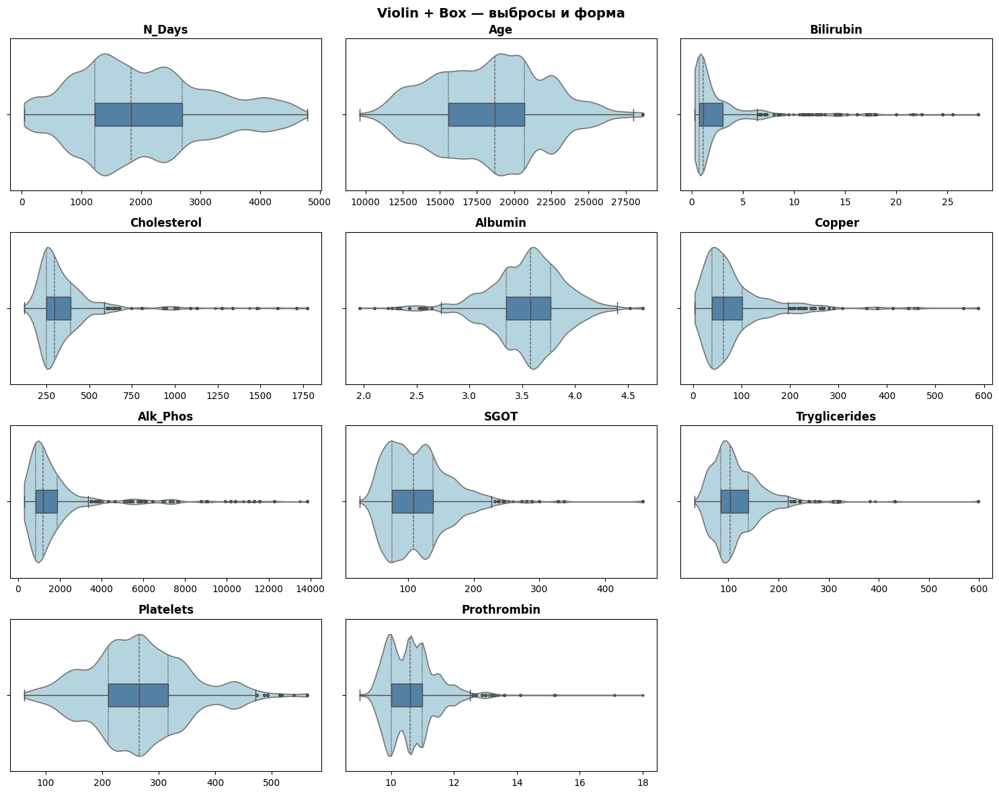

In [32]:
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
for ax, c in zip(axes.flatten(), num_cols):
    sns.violinplot(x=df_clean[c], ax=ax, inner='quartile', color='lightblue', cut=0)
    sns.boxplot(x=df_clean[c], ax=ax, width=0.15, color='steelblue', fliersize=2)
    ax.set_title(c, fontsize=12, fontweight='bold')
    ax.set_xlabel('')
for ax in axes.flatten()[len(num_cols):]:
    ax.set_visible(False)
plt.suptitle('Violin + Box — выбросы и форма', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## **4.4 Тесты нормальности (формальная проверка)**

**Что смотреть:** если `p < 0.05` — гипотеза нормальности отвергается. В этом датасете все признаки ненормальны → нужны лог-преобразования или непараметрические тесты.

In [33]:
results = []
for c in num_cols:
    s = df_clean[c].dropna()
    s_sample = s.sample(min(5000, len(s)), random_state=RANDOM_STATE)  # ограничение для Shapiro
    results.append({
        'feature': c,
        'Shapiro_p':  stats.shapiro(s_sample).pvalue,
        'DAgostino_p': stats.normaltest(s).pvalue,
        'skew': s.skew(),
        'kurt': s.kurt(),
        'is_normal_5%': stats.normaltest(s).pvalue > 0.05,
    })
pd.DataFrame(results).round(4)


,feature,Shapiro_p,DAgostino_p,skew,kurt,is_normal_5%
0,N_Days,0.0,0.0,0.4487,-0.4940,False
1,Age,0.0,0.0,0.0841,-0.4974,False
2,Bilirubin,0.0,0.0,3.3397,12.9088,False
3,Cholesterol,0.0,0.0,3.6797,18.1623,False
4,Albumin,0.0,0.0,-0.5611,1.3396,False
5,Copper,0.0,0.0,2.7017,10.2130,False
6,Alk_Phos,0.0,0.0,3.1956,11.5998,False
7,SGOT,0.0,0.0,1.5348,5.8168,False
8,Tryglicerides,0.0,0.0,2.6339,15.0481,False
9,Platelets,0.0,0.0,0.4200,0.3306,False


## **4.5 Визуализация категориальных признаков (bar)**

**Что смотреть:** визуальный дисбаланс, редкие бары (< 5 %), «плоские» признаки (бинарные с сильным перекосом, например `Ascites ≈ 90 % N`).

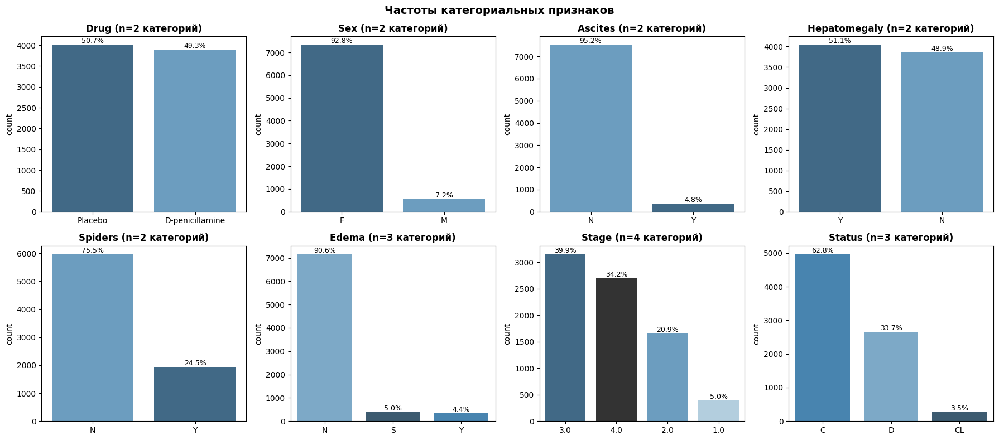

In [34]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.flatten(), cat_cols):
    order = df_clean[c].value_counts().index
    sns.countplot(data=df_clean, x=c, order=order, ax=ax,
                  palette='Blues_d', hue=c, legend=False)
    ax.set_title(f'{c} (n={df_clean[c].nunique()} категорий)',
                 fontsize=12, fontweight='bold')
    ax.set_xlabel('')
    for p in ax.patches:
        h = p.get_height()
        ax.annotate(f'{h/len(df_clean)*100:.1f}%',
                    (p.get_x()+p.get_width()/2, h),
                    ha='center', va='bottom', fontsize=9)
plt.suptitle('Частоты категориальных признаков', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## **4.6 Целевые признаки: Status и N_Days (survival-контекст)**

**Что смотреть:** доля `D` (смерть) vs `C` (цензурировано) — главный дисбаланс для задачи выживаемости. `N_Days` имеет длинный правый хвост (максимум ~4500 дней) — это нормально для survival-данных.

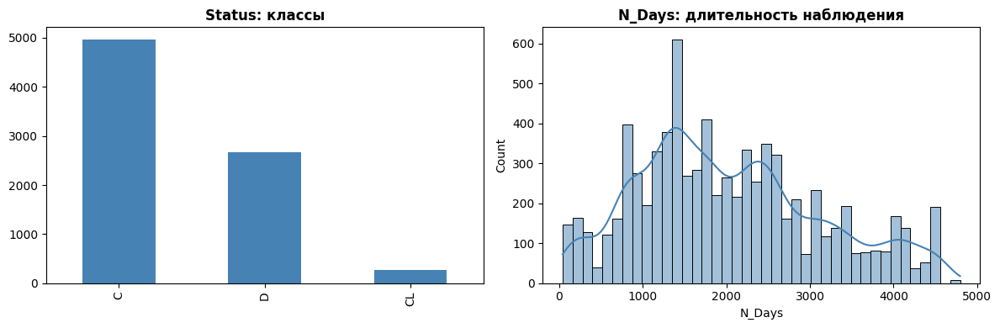

In [35]:
# 1. Распределение классов Status
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_clean['Status'].value_counts().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Status: классы', fontsize=12, fontweight='bold')
axes[0].set_xlabel('')

# 2. Длительность наблюдения
sns.histplot(df_clean['N_Days'], bins=40, kde=True, ax=axes[1], color='steelblue')
axes[1].set_title('N_Days: длительность наблюдения', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## **4.7 Kaplan-Meier кривые выживаемости**

Survival-специфичный график, который отображает выживаемость по стадии цирроза (`Stage`). Оценивает вероятность того, что событие (`D` — смерть) ещё не наступило к моменту `t` с учётом цензурирования.

**Что смотреть:** скорость падения кривых и их разделение по группам. Если кривые разных стадий хорошо разделяются — `Stage` значимый прогностический признак.

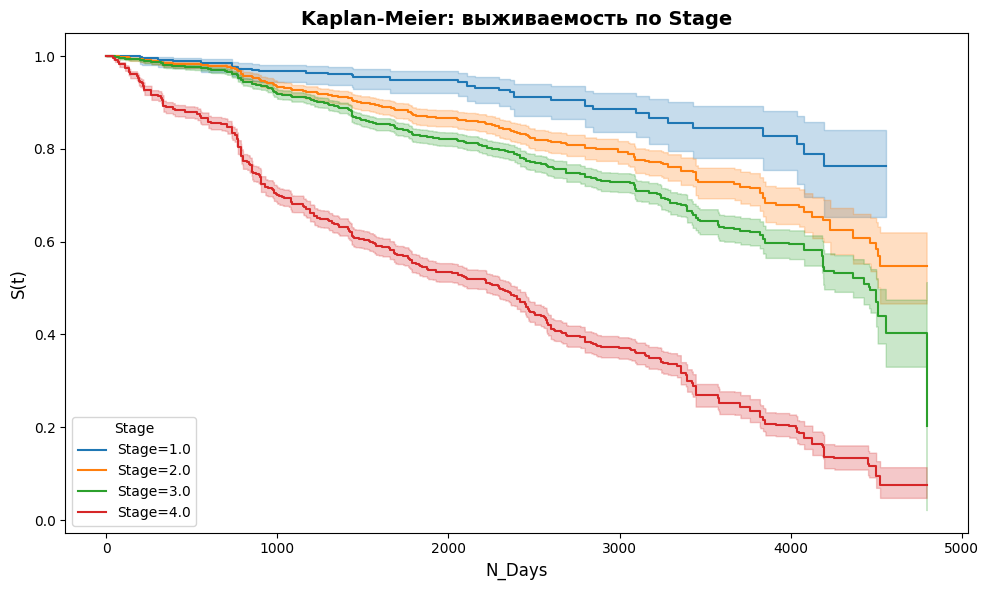

In [36]:
# lifelines — стандартная библиотека survival-анализа
from lifelines import KaplanMeierFitter

kmf = KaplanMeierFitter()

# 1. K-M по стадии цирроза
fig, ax = plt.subplots(figsize=(10, 6))
for stage, group in df_clean.groupby('Stage'):
    event = (group['Status'] == 'D').astype(int)
    kmf.fit(durations=group['N_Days'], event_observed=event,
          label=f'Stage={stage}')
    kmf.plot_survival_function(ax=ax)
ax.set_title('Kaplan-Meier: выживаемость по Stage',
             fontsize=14, fontweight='bold')
ax.set_xlabel('N_Days', fontsize=12)
ax.set_ylabel('S(t)', fontsize=12)
ax.legend(title='Stage')
plt.tight_layout()
plt.show()


# **Часть 5. Многомерный анализ**

## **5.1 Корреляционный анализ с φk (phik)**

In [37]:
# Импорт библиотеки phik
import phik
from phik import resources, report


### Почему матрица построена по итоговому набору признаков

Матрицу связей строим не по всем 35 столбцам, а по тем 15 признакам, которые отобраны для модели в блоках 2.5, 3.11 и 3.14. Причина простая: если положить в матрицу и показатель, и его копию, половина ячеек покажет почти единичную связь между ними. Такая картинка загораживает настоящие взаимосвязи данных — она говорит не о пациентах, а о том, что мы сами создали дубликаты.

В матрицу дополнительно включён `N_Days`, хотя в модель он не идёт. Он нужен здесь как наглядное напоминание о выводах блока 3.11: связь периода с исходом одна из самых сильных, а сам период — следствие исхода, а не его причина.

**Цель в матрице — бинарная.** Вместо трёхклассового `Status` используется `Event` (0 — жив со своей печенью, 1 — трансплантация или смерть). Это та цель, которую модели предсказывают начиная со стадии 2, поэтому матрица показывает ровно те связи, с которыми они будут работать.

**Что такое φk.** Обычная корреляция Пирсона считает только линейную связь между числами, а коэффициент Крамера — только между категориями. φk (фи-ке) работает в обоих случаях и умеет улавливать нелинейные связи, поэтому одна матрица описывает и лабораторные показатели, и бинарные признаки, и цель.

| Исключено из матрицы | Почему |
|---|---|
| `Bilirubin`, `Copper`, `Alk_Phos`, `SGOT`, `Cholesterol`, `Tryglicerides` | их лог-варианты взяты в модель как основные |
| `Age`, `Edema`, `is_severe` | их заменяют `Age_years`, `Edema_num`, `Stage` |
| `Ascites`, `Ascites_Y` | дублируют отёки, исключены в блоке 3.11 |
| `is_dead` | утечка цели |
| `Drug`, `id` | неинформативны (блок 3.12) |
| `Status` | заменён бинарной целью `Event` (блок 3.9) |


### Матрица корреляций φk

В матрице φk: 17 столбцов (15 признаков модели + период + цель)
Исключено как дубликаты или неинформативные (17): ['Age', 'Alk_Phos', 'Ascites', 'Ascites_Y', 'Bilirubin', 'Cholesterol', 'Copper', 'Drug', 'Edema', 'Hepatomegaly', 'SGOT', 'Sex', 'Spiders', 'Status', 'Tryglicerides', 'is_dead', 'is_severe']


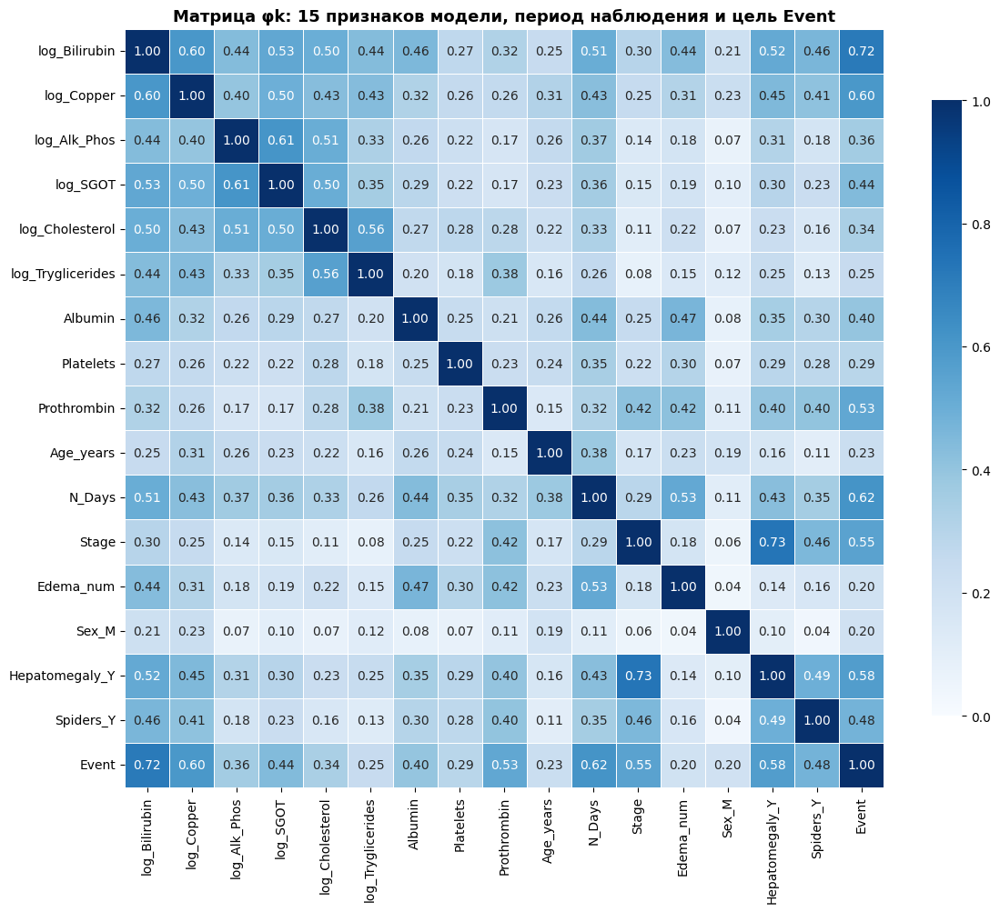

Связь каждого признака с целью (по убыванию):


,φk с Event
log_Bilirubin,0.718
N_Days,0.616
log_Copper,0.601
Hepatomegaly_Y,0.576
Stage,0.554
Prothrombin,0.529
Spiders_Y,0.480
log_SGOT,0.442
Albumin,0.398
log_Alk_Phos,0.363



Самые тесные пары между признаками:


,,φk
признак 1,признак 2,
Stage,Hepatomegaly_Y,0.733
log_Alk_Phos,log_SGOT,0.611
log_Bilirubin,log_Copper,0.603
log_Cholesterol,log_Tryglicerides,0.562
log_Bilirubin,log_SGOT,0.528
N_Days,Edema_num,0.527


In [38]:
# df_unique — выборка без дубликатов по id

df_unique = df_clean.drop_duplicates(subset='id')

# Итоговый набор признаков модели + период для наглядности + бинарная цель
interval_cols = [c for c in FINAL_FEATURES if df_unique[c].nunique() > 6] + ['N_Days']
binary_cols = [c for c in FINAL_FEATURES if c not in interval_cols]
categorical_cols = binary_cols + ['Event']

subset_cols = interval_cols + categorical_cols
dropped = [c for c in df_unique.columns if c != 'id' and c not in subset_cols]
print(f'В матрице φk: {len(subset_cols)} столбцов (15 признаков модели + период + цель)')
print(f'Исключено как дубликаты или неинформативные ({len(dropped)}): {sorted(dropped)}')

# Считаем phik-матрицу в один поток (njobs=1), чтобы обойти баг сериализации в pandas 3+
phik_matrix = df_unique[subset_cols].phik_matrix(
    interval_cols=interval_cols,
    njobs=1
)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(phik_matrix, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1,
            square=True, linewidths=0.5, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Матрица φk: 15 признаков модели, период наблюдения и цель Event',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Сортировка связей с целью — самый полезный срез матрицы
with_target = phik_matrix['Event'].drop('Event').sort_values(ascending=False)
print('Связь каждого признака с целью (по убыванию):')
display(with_target.round(3).to_frame('φk с Event'))

# Самые тесные пары между самими признаками
feat_only = phik_matrix.drop(index='Event', columns='Event')
UPPER = np.triu(np.ones_like(feat_only, dtype=bool), k=1)
top_pairs = feat_only.where(UPPER).stack().sort_values(ascending=False).head(6)
print('\nСамые тесные пары между признаками:')
display(top_pairs.round(3).to_frame('φk').rename_axis(['признак 1', 'признак 2']))


### Как читать матрицу

| Значение φk | Что это значит |
|---|---|
| 0.00 – 0.15 | связи практически нет |
| 0.15 – 0.30 | слабая связь |
| 0.30 – 0.50 | умеренная связь |
| выше 0.50 | сильная связь |

**Что видно в матрице и что из этого следует.**

1. **Сильнее всего с исходом связан логарифм билирубина (0.718), затем медь (0.601), увеличение печени (0.576), стадия (0.554) и протромбин (0.529).** Это показатели работы и повреждения печени. Клинически ожидаемо: чем тяжелее поражение органа, тем выше билирубин и медь и тем хуже свёртываемость крови. Модель опирается на правильные данные.

2. **Период наблюдения стоит вторым по силе (0.616)** — и это ровно та ловушка, о которой говорилось в блоке 3.11. Сильная связь не означает, что период полезен как прогноз: он возникает после исхода, а не до него.

3. **Между собой признаки связаны умеренно.** Самая тесная пара — `Stage` и `Hepatomegaly_Y` с φk 0.733, затем `log_Alk_Phos` и `log_SGOT` (0.611), `log_Bilirubin` и `log_Copper` (0.603).

4. **Бинарные признаки связаны с исходом слабее лабораторных показателей, но связь не нулевая** — они остаются в модели.

### Почему φk показывает пару выше 0.6, а корреляция Пирсона — нет

В блоке 3.11 проверка на мультиколлинеарность по корреляции Пирсона не нашла ни одной пары выше 0.6, а здесь `Stage` и `Hepatomegaly_Y` дают 0.733. Противоречия нет: меры отвечают на разные вопросы.

Корреляция Пирсона меряет **линейную** связь между числами и равна нулю, если связь нелинейна. φk меряет **любую** зависимость, включая нелинейную и немонотонную. Стадия фиброза и увеличение печени связаны не по прямой: у пациента со стадией 3 печень может быть увеличена или нет, а при стадии 4 — почти всегда увеличена. Это ступенчатая зависимость, Пирсон её не видит, φk видит.

Для линейной модели важна именно линейная составляющая, поэтому порог 0.6 в блоке 3.11 применялся к корреляции Пирсона. φk-матрица здесь служит другой цели — описать структуру данных целиком, а не отобрать признаки.

**Практический вывод.** Пара `Stage` — `Hepatomegaly_Y` остаётся в модели: дублирования информации нет, признаки измеряют разное (гистологическая стадия против физикального осмотра). Нелинейная связь между ними — клинический факт, а не дефект данных.


# **Часть 6. Сегментированный анализ**

## **6.1 Стадии и медианное время наблюдения**

**Что смотреть:** Stage 1 должен давать наибольшую медиану `N_Days`, Stage 4 — наименьшую. Если порядок нарушен — либо шум из-за малых подгрупп, либо данные требуют пересмотра.

In [39]:
# Топ-5 стадий по медианной выживаемости (N_Days)
top_stages_by_days = (
    df_clean[df_clean['N_Days'] != 0]
      .groupby('Stage', observed=True)['N_Days']
      .median()
      .sort_values(ascending=False)
      .head(5)
)

print('Топ-5 стадий по медианной выживаемости (N_Days):')
print(top_stages_by_days.round(1))

# Ключевые лабораторные признаки для сравнения
features_for_comparison = ['Bilirubin', 'Albumin', 'Prothrombin',
                           'Platelets', 'Copper', 'SGOT']

# Медианы по группам
selected_stages = top_stages_by_days.index.tolist()
stage_stats = (df_clean[df_clean['Stage'].isin(selected_stages)]
               .groupby('Stage', observed=True)[features_for_comparison]
               .median())

print('\nМедианы ключевых признаков по стадиям:')
display(stage_stats.round(2))


Топ-5 стадий по медианной выживаемости (N_Days):
Stage
1.0    2255.0
2.0    2221.0
3.0    1951.0
4.0    1455.0
Name: N_Days, dtype: float64

Медианы ключевых признаков по стадиям:


,Bilirubin,Albumin,Prothrombin,Platelets,Copper,SGOT
Stage,,,,,,
1.0,0.8,3.64,10.5,271.0,52.0,93.00
2.0,0.9,3.63,10.4,271.0,52.0,97.65
3.0,0.9,3.61,10.4,269.0,57.0,102.30
4.0,2.0,3.48,11.0,233.0,76.0,120.00


## **6.2 Radar Chart: профили стадий**

**Radar Chart** — удобный инструмент для сравнения многомерных профилей.
Каждая стадия представлена как «паутина», где:
- Оси — клинические признаки.
- Расстояние от центра — медианный percentile rank признака.
- Форма «паутины» — уникальный профиль группы пациентов.

**Зачем percentile rank:** признаки измеряются в разных единицах (мг/дл, Ед/л, ×1000/мкл), поэтому приводим каждый к единой шкале [0, 1].

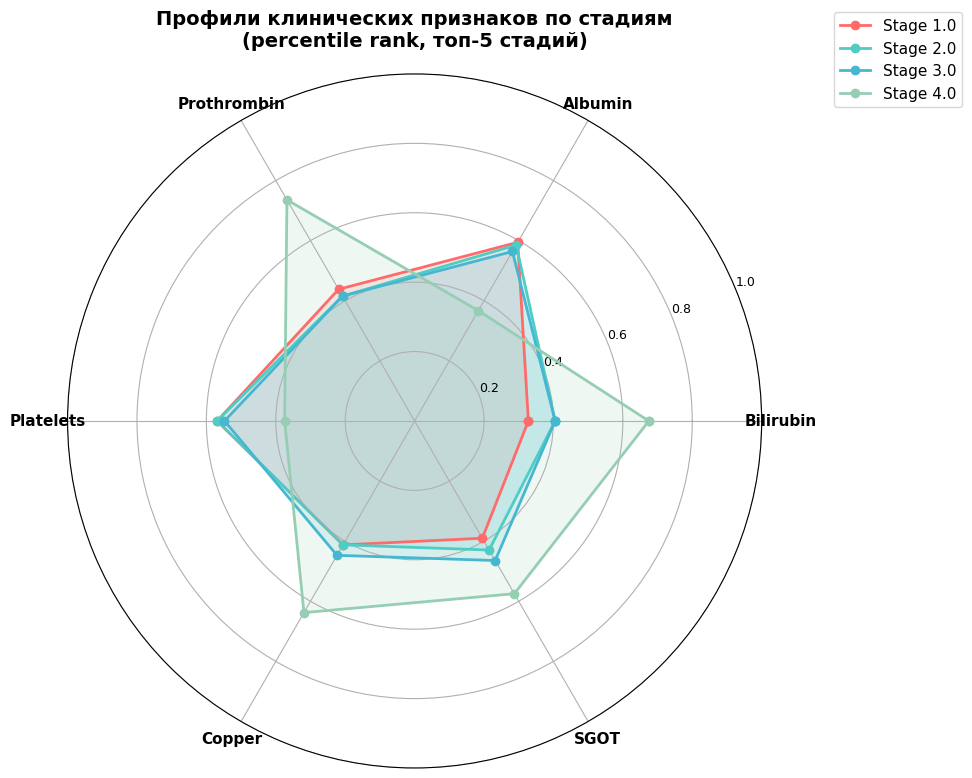

In [40]:
radar_features = ['Bilirubin', 'Albumin', 'Prothrombin', 'Platelets', 'Copper', 'SGOT']

# 1. Нормализация: percentile rank по всей выборке -> [0, 1]
df_radar = df_clean.copy()
for c in features_for_comparison:
    df_radar[c] = df_radar[c].rank(pct=True)

# 2. Медианы по группам в нормализованной шкале
group_stats = (df_radar[df_radar['Stage'].isin(selected_stages)]
    .groupby('Stage', observed=True)[features_for_comparison]
    .median())

# 3. RADAR CHART
categories = features_for_comparison
N = len(categories)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]  # замыкаем круг

colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7']

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

for idx, group in enumerate(selected_stages):
    values = group_stats.loc[group].values.flatten().tolist()
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2,
            label=f'Stage {group}', color=colors[idx])
    ax.fill(angles, values, alpha=0.15, color=colors[idx])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=11, fontweight='bold')
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=9)

ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=11)
ax.set_title('Профили клинических признаков по стадиям\n'
    '(percentile rank, топ-5 стадий)',
    fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.show()


# **Часть 7. Автоматизированная проверка качества данных**

In [41]:
# Импорт
from ydata_profiling import ProfileReport


/tmp/ipykernel_144993/1890097276.py:2: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


## **7.1 Генерация отчёта**

In [42]:
# Генерация отчёта (может занять 1-2 минуты)
profile = ProfileReport(
    df_clean,
    title='Cirrhosis Outcomes EDA Report',
    explorative=True,
    correlations={
        'auto': {'calculate': False},
        'phi_k': {'calculate': True},
    },
)
profile


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/35 [00:00<?, ?it/s]

100%|██████████| 35/35 [00:00<00:00, 198916.86it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [43]:
# Сохранение отчёта в HTML-файл
profile.to_file('cirrhosis_eda_report.html')


Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

ydata-profiling автоматически проверяет пропуски, дубликаты, распределения, корреляции и предупреждает о проблемных колонках. Это надёжный чек-лист, который помогает не упустить очевидные проблемы качества данных.

# **Итоги анализа**

## **1. Что можно сказать о пациентах и данных**

- **Исходы распределены неравномерно, но после объединения классов баланс приемлемый.** Живы на конец наблюдения 4 965 пациентов (62.8 %), умерли 2 665 (33.7 %), перенесли трансплантацию 275 (3.5 %). Трёхклассовая задача страдала бы от редкого класса в 3.5 %; после объединения «трансплантация или смерть» в одно событие баланс составляет 62.8 % против 37.2 % — рабочее соотношение для классификации.

- **Трансплантация — не отдельный исход, а конкурирующий риск.** Пациент получает орган тогда, когда без пересадки погибнет. Профили пациента на трансплантации и умершего по анализам почти совпадают: логарифм билирубина 1.361 против 1.435, альбумин 3.57 против 3.45. Различает их возраст — 41.4 против 52.7 лет. Трёхклассовая модель тратила бы ёмкость на различение по возрасту, а не по тяжести болезни. Целевая переменная проекта — **выживание со своей печенью** (`Event`: 0 — жив, 1 — трансплантация или смерть).

- **Результаты анализов распределены крайне неровно.** У большинства пациентов билирубин и медь в пределах нормы, но у небольшой группы отклонения в десятки раз. Такие показатели перед моделированием приводят к логарифмической шкале — иначе единичные тяжёлые пациенты вытягивают всю модель за собой.

- **Стадия поражения печени согласуется с анализами**: чем выше стадия, тем выше билирубин, медь и протромбиновое время и тем ниже альбумин и тромбоциты. Данные внутренне непротиворечивы — это важный признак их качества.

- **Стадия значимо влияет на выживаемость.** Кривые выживаемости по стадиям визуально расходятся — чем выше стадия, тем быстрее падает кривая, значит стадия — сильный прогностический признак.

- **Большинство «выбросов» — это тяжёлые пациенты, а не ошибки ввода.** Формальное правило отсечения выбросов удалило бы самых больных, то есть наиболее интересных для задачи. Мы их сохранили.

- **Препарат не связан с исходом.** Распределение событий в группах препарата и плацебо статистически неразличимо (вероятность 0.057 при пороге 0.05, доли 38.3 % и 36.2 %). Это подтверждает корректность рандомизации исследования, но делает признак бесполезным для прогноза.

## **2. Какие признаки сильнее всего влияют на прогноз**

Рейтинг построен по четырём независимым мерам связи с целью (блок 3.13). Первые места по φk и точечно-биссериальной корреляции совпадают; взаимная информация выделяет дополнительно `log_SGOT`, `Platelets` и `log_Cholesterol`:

| Место | Признак | φk | Взаимная информация | Точечно-биссериальная корреляция | Отношение шансов / Крамера V |
|---|---|---|---|---|---|
| 1 | `log_Bilirubin` | 0.718 | 0.176 | 0.531 | 29.1 |
| 2 | `log_Copper` | 0.601 | 0.160 | 0.415 | 15.0 |
| 3 | `Prothrombin` | 0.529 | 0.092 | 0.373 | 6.9 |
| 4 | `Stage` | 0.554 | 0.073 | 0.342 | 0.38 |
| 5 | `Hepatomegaly_Y` | 0.576 | 0.080 | 0.392 | 0.39 |
| 6 | `log_SGOT` | 0.442 | 0.135 | 0.331 | 7.1 |
| 7 | `Spiders_Y` | 0.480 | 0.050 | 0.319 | 0.32 |
| 8 | `Albumin` | 0.398 | 0.078 | −0.288 | 0.25 |
| 9 | `log_Alk_Phos` | 0.363 | 0.117 | 0.221 | 4.0 |
| 10 | `log_Cholesterol` | 0.340 | 0.125 | 0.184 | 2.2 |

**`log_Bilirubin` — главный предиктор по всем мерам.** Отношение шансов 29.1: у пациента с билирубином из верхнего квартиля событие наступает в 77.5 % случаев, из нижнего — в 10.6 %. Это согласуется с клинической практикой: билирубин — маркёр функции печени, его рост указывает на декомпенсацию.

**Протромбин и стадия фиброза — маркёры тяжести.** Повышенное протромбиновое время (отношение шансов 6.9) и высокая стадия связаны с событием независимо от билирубина. Оба признака входят в шкалу Чайлда — Пью, которая используется для прогноза при циррозе.

**Альбумин и тромбоциты связаны с целью отрицательно.** Отношение шансов 0.25 и 0.41: чем выше показатель, тем ниже риск события. Альбумин синтезируется печенью, его падение означает декомпенсацию; тромбоцитопения при циррозе связана с портальной гипертензией.

**Что это означает для модели.** Две независимые меры — нелинейная (φk) и линейная (точечно-биссериальная корреляция) — дают полностью совпадающий топ-5. Взаимная информация, чувствительная к нелинейностям, выделяет дополнительно `log_SGOT` и `Platelets`. Признаки-лидеры не обязаны быть одинаково сильными во всех мерах: `log_SGOT` поднимается на третье место по взаимной информации и опускается на шестое по φk, что указывает на нелинейную составляющую связи.

## **3. Какие признаки отобраны для модели и почему**

Из 35 столбцов очищенного датасета в модель идут **15**. Отбор опирался на три независимых основания, и каждое отсеяло своё:

| Основание | Сколько и какие столбцы отсечены |
|---|---|
| **Дублирование** — один и тот же факт записан дважды | 12 столбцов: шесть анализов, у которых в модель идёт логарифм, а не исходное значение; `Age` (заменён `Age_years`); `Edema` (заменён `Edema_num`); `is_severe` (заменён `Stage`); `Sex`, `Hepatomegaly`, `Spiders` (заменены числовыми кодами `Sex_M`, `Hepatomegaly_Y`, `Spiders_Y`) |
| **Избыточная пара** | `Ascites` и `Ascites_Y` — оба повторяют информацию об отёках (φk 0.429); оставлен только `Edema_num` |
| **Нет связи с исходом** | `Drug` (φk 0.029, вероятность 0.057), `id` (технический номер) |
| **Подглядывание в ответ** | `is_dead` — это буквально половина ответа; `N_Days` — период наблюдения, известен только после исхода |

**Правило «одна информация — один столбец» — главное в этом отборе.** Инженерные признаки (логарифмы, возраст в годах, флаги) сделаны для удобства человека, но модель читает числа и не различает «удобную» и «исходную» форму одного и того же факта. Положить в модель и билирубин, и его логарифм — всё равно что спросить у пациента одно и то же дважды и сделать вид, что получил два независимых ответа. Вес при признаке перестаёт отвечать на вопрос «как этот показатель влияет на исход», а выводы из такой модели становятся ненадёжными.

**Проверка кодирования.** Пары «категория — её числовой код» дают одинаковые меры связи с точностью до четвёртого знака: `Sex` 0.1997 и `Sex_M` 0.1997, `Edema` 0.1967 и `Edema_num` 0.1967. Числовое кодирование не меняет связь с целью — значит, выбирать между вариантами пары нужно по числу столбцов, а не по силе связи.

**Почему из пары «асцит — отёки» убран асцит.** Проверка на пяти частях данных (кросс-валидация) показала: без асцита качество не меняется вообще (ROC-AUC 0.8781 против 0.8781, разница меньше разброса между частями проверки ±0.0051), а без отёков модель хуже (ROC-AUC 0.8773, лог-потеря 0.4262 против 0.4217). Более простой набор при равном качестве предпочтительнее.

## **4. Решение по периоду наблюдения**

Период наблюдения — сколько дней пациент провёл под наблюдением до развязки — это самый обманчивый столбец датасета.

Он очень сильно связан с исходом (φk 0.616, второе место после билирубина). Но связь работает **в обратную сторону**: не период влияет на исход, а исход определяет период. Пациент, умерший на 400-й день, наблюдаться дольше не мог физически.

Проверки подтверждают это:

- Если приравнять период у всех пациентов к максимальному (4 795 дней), исходы не изменятся ни у одного — период на них не влияет.
- Среди пациентов с одинаковым периодом около 70 % живы и около 25 % умерли: один и тот же период даёт все исходы.
- 90 % умерших наблюдались от 140 до 3 820 дней — интервалы классов перекрываются, по периоду их не разделить.

**Принято решение: период в модель исхода не включать.** Контрольный опыт на стадии 3 проверит, что качество от удаления периода не страдает.

Рассматривался и вариант «двухэтапного» использования: сначала предсказать исход, а зная его — предсказать период. Проверка показала, что период объясняется клиническими данными лишь на 22 %, а знание исхода добавляет ещё 0.8 процентного пункта. Выигрыш не оправдывает удвоения сложности, и от этого варианта отказались.

**Почему фиксируем явно.** Модель, использующая период, показывает красивые цифры на этих данных, но неприменима к пациенту, который пришёл на приём сегодня: его период ещё не наступил.

## **5. Рекомендации для стадий моделирования**

| Вопрос | Рекомендация | Обоснование |
|---|---|---|
| Данные | Читать `train_model.parquet` (15 признаков + `Event`) | набор собран и обоснован; цель бинарная |
| Метод | Не использовать оценку по числу (линейную регрессию); использовать классификацию | исход — категория, а не число; проверка предпосылок на стадии 2 |
| Разбиение данных | Делить стратифицированно | при балансе 63/37 разброс долей между частями меньше, но стратификация остаётся дешёвой гарантией |
| Основная метрика | ROC-AUC | не зависит от порога и от баланса классов, оценивает упорядочивание пациентов по риску |
| Дополнительные метрики | Лог-потеря (калибровка вероятностей), F-мера, метрика Брайера | лог-потеря и Брайер наказывают за уверенные неверные ответы; F-мера нужна для сравнения с порогом |
| Доля верных ответов | Не использовать как основную | при балансе 63/37 модель «всегда жив» даёт 0.628 — это не качество |
| Порог решения | Подбирать по соотношению цены пропущенного события и ложной тревоги | пропустить пациента с событием дороже, чем ошибиться в другую сторону; конкретное соотношение задаётся клинически |
| Калибровка | Проверять кривой надёжности и метрикой Брайера | вероятность нужна врачу как число, а не только как рейтинг |

## **6. Ограничения анализа**

- **Данные синтетические** — сгенерированы моделью по мотивам реального датасета UCI. Редкие классы и хвосты распределений могут отличаться от реальной популяции пациентов.
- **Трансплантация и смерть объединены в одно событие.** Модель не различает «пациенту нужен орган» и «пациент умер». Для задачи листинга на трансплантацию такая модель не подходит напрямую: она отвечает на вопрос «сохранится ли своя печень», а не «какой именно исход наступит».
- **Период наблюдения и исход описывают только конец наблюдения.** Причинный эффект препарата в рамках этой работы не оценивался: нас интересует прогноз, а не лечение.
- **Матрицы связей и радар-диаграммы — визуальные инструменты.** Статистическая значимость связей проверялась тестами в блоках 3.11 и 3.12, но причинно-следственные выводы из них не делаются.
